# Defesa rápida: perguntas, respostas e evidências
**João Pedro Castro e Vitor Neves • IBMEC • Prof. Marcelo Guzella**

Material complementar à apresentação oficial. Use a seção correspondente à pergunta, sem percorrer tudo durante a fala. São 12 temas, com respostas curtas e evidências já calculadas. A apresentação principal continua com dez slides.

**Como usar:** execute “Preparação” uma vez e depois apenas a seção desejada. Este arquivo contém uma cópia dos resultados registrados, funciona sem baixar a base e não retreina modelos. É uma consulta reproduzível, não uma nova avaliação independente. O estudo completo e a demonstração de treinamento ficam no notebook original, seções 20 e 24.

**Atalhos:** 1 dados • 2 preparação • 3 split e teste • 4 CV • 5 classificadores • 6 regressão • 7 métricas • 8 calibração • 9 grupos • 10 dinheiro • 11 incerteza • 12 ética e defesa.

Atenção especial: campeão vem da validação; teste já consultado é retrospectivo; benefício é simulado; grupos não são classes de fraude.


### Preparação — execute uma vez
A cópia abaixo vem de `results/`, com hashes dos arquivos de origem. Os números não foram recalculados por novo treinamento. `tabela` apenas formata as evidências para leitura.

In [1]:
import json
from IPython.display import display, Markdown, Image
import base64
IMAGENS = json.loads('{"regression_residuals": "...", "classification_diagnostics": "..."}')
def grafico(nome):
    display(Image(data=base64.b64decode(IMAGENS[nome])))
# Cópia congelada dos resultados do experimento; nenhuma base pessoal ou credencial.
DADOS = json.loads('{"audit.json": {"raw_rows": 590540, "raw_frauds": 20663, "raw_fields": 456, "raw_time_min": 86400, "raw_time_max": 15811131, "raw_missing_fraction": 0.31105068484534737, "transaction_id_present": false, "sample_rows": 116533, "sample_frauds": 4046, "sample_fraction": 0.19733294950384395, "cut_days": [108, 135, 153], "sample_fraud_amount": 606965.6220000001, "days": 180, "duplicated_selected_feature_vectors": 0, "splits": [{"split": "calibration", "n": 9883, "days": 18, "start": 135, "end": 152, "frauds": 335, "amount": 49492.762}, {"split": "test", "n": 15915, "days": 28, "start": 153, "end": 180, "frauds": 530, "amount": 78851.255}, {"split": "train", "n": 74365, "days": 107, "start": 1, "end": 107, "frauds": 2532, "amount": 362072.718}, {"split": "validation", "n": 16370, "days": 27, "start": 108, "end": 134, "frauds": 649, "amount": 116548.887}]}, "config.json": {"curricular_revision": "15 techniques; test period previously inspected in earlier version; retrospective evaluation, not a fresh holdout", "seed": 42, "sample": "every fifth source row; no stratification", "training_budget": 30000, "timeline": "whole relative days 60% train,15% validation,10% calibration,15% test", "capacity": 0.02, "cost": 2.0, "efficacy": 0.8, "false_positive_penalty": 0.0, "selection_classifier": "largest labeled fraud amount captured with 2% daily review in validation", "selection_regressor": "smallest validation MSE; target TransactionAmt*isFraud", "monetary_unit": "USD according to Empulse documentation; no conversion to BRL"}, "classification_selection.json": {"winner": "HistGradientBoosting", "params": {"Logistic": {"C": 1.0}, "LDA": {"shrinkage": "auto"}, "HistGradientBoosting": {"max_leaf_nodes": 31, "l2_regularization": 20.0}, "KNN": {"n_neighbors": 45}, "GaussianNB": {"var_smoothing": 0.001}}, "thresholds": {"Logistic": 0.19999999999999996, "LDA": 0.5599999999999999, "HistGradientBoosting": 0.19999999999999996, "KNN": 0.15999999999999998, "GaussianNB": 0.45999999999999996}, "validation_selection_scores": {"Logistic": 56719.291, "LDA": 37045.073, "HistGradientBoosting": 60822.713, "KNN": 49513.148, "GaussianNB": 27402.476000000002}, "budget_final": 30000}, "regression_selection.json": {"winner": "RandomForest", "params": {"Linear": {}, "Ridge": {"alpha": 100.0}, "Lasso": {"alpha": 0.1}, "DecisionTree": {"max_depth": 5, "min_samples_leaf": 50}, "RandomForest": {"max_depth": 15, "min_samples_leaf": 5}, "HistGradientBoosting": {"max_leaf_nodes": 15, "l2_regularization": 50.0}}, "thresholds": {}, "validation_selection_scores": {"Linear": -4112.466701767091, "Ridge": -4113.2835200724, "Lasso": -4130.666541306266, "DecisionTree": -3786.7653517468198, "RandomForest": -3710.084048983581, "HistGradientBoosting": -3769.342231363352}, "budget_final": 30000}, "financial_bootstrap.json": {"main_policy": "ML_ExpectedAmount", "comparator": "LargestAmount", "capacity": 0.02, "incremental_benefit": 18699.657600000002, "ci95_low": 13862.060780000002, "ci95_high": 23765.044719999998, "days": 28, "block_days": 7, "note": "Exploratory paired circular bootstrap; few independent temporal blocks; no causal claim"}, "logistic_comparator_bootstrap.json": {"candidate": "HistGradientBoosting", "reference": "Logistic", "incremental_benefit": 7132.379199999999, "ci95_low": 4357.875360000003, "ci95_high": 10016.030959999996, "note": "Additional diagnostic after primary evaluation; does not replace original comparator or winner"}, "training_diagnostics.json": {"note": "Post hoc descriptive diagnostic. Frozen parameters and original final training sample. Test predictions match saved predictions. No reselection.", "rows": [{"task": "classification", "model": "HistGradientBoosting", "split": "Ajuste final (30 mil)", "accuracy": 0.9787, "precision": 0.7242044358727098, "recall": 0.6802536231884058, "F1": 0.7015413358243812, "ROC_AUC": 0.9560568190823262, "AP": 0.7513024380257569, "Brier": 0.01698880793708129, "threshold": 0.19999999999999996}, {"task": "classification", "model": "HistGradientBoosting", "split": "Teste posterior", "accuracy": 0.9643103989946591, "precision": 0.4634615384615385, "recall": 0.4547169811320755, "F1": 0.45904761904761904, "ROC_AUC": 0.8759909492828719, "AP": 0.4539997764698402, "Brier": 0.023108953227230635, "threshold": 0.19999999999999996}, {"task": "regression", "model": "RandomForest", "split": "Ajuste final (30 mil)", "MAE": 6.223049940178524, "MSE": 932.7177117675702, "RMSE": 30.540427498114205, "R2": 0.5903674653395767}, {"task": "regression", "model": "RandomForest", "split": "Teste posterior", "MAE": 8.295078610936244, "MSE": 1597.1016921430496, "RMSE": 39.96375473029342, "R2": 0.24650338222978663}]}, "classification_cv.csv": [{"model": "Logistic", "params": "{\\"C\\": 0.1}", "fold": "1", "score": "-0.3542031035273529", "train_end": "59", "val_start": "60"}, {"model": "Logistic", "params": "{\\"C\\": 0.1}", "fold": "2", "score": "-0.3828375015924859", "train_end": "75", "val_start": "76"}, {"model": "Logistic", "params": "{\\"C\\": 0.1}", "fold": "3", "score": "-0.26668299979318894", "train_end": "91", "val_start": "92"}, {"model": "Logistic", "params": "{\\"C\\": 1.0}", "fold": "1", "score": "-0.36035816227826345", "train_end": "59", "val_start": "60"}, {"model": "Logistic", "params": "{\\"C\\": 1.0}", "fold": "2", "score": "-0.3948973938241104", "train_end": "75", "val_start": "76"}, {"model": "Logistic", "params": "{\\"C\\": 1.0}", "fold": "3", "score": "-0.2644172234083015", "train_end": "91", "val_start": "92"}, {"model": "LDA", "params": "{\\"shrinkage\\": 0.1}", "fold": "1", "score": "-0.33544232834412796", "train_end": "59", "val_start": "60"}, {"model": "LDA", "params": "{\\"shrinkage\\": 0.1}", "fold": "2", "score": "-0.3421436403200786", "train_end": "75", "val_start": "76"}, {"model": "LDA", "params": "{\\"shrinkage\\": 0.1}", "fold": "3", "score": "-0.25290356335460756", "train_end": "91", "val_start": "92"}, {"model": "LDA", "params": "{\\"shrinkage\\": \\"auto\\"}", "fold": "1", "score": "-0.3434792778461995", "train_end": "59", "val_start": "60"}, {"model": "LDA", "params": "{\\"shrinkage\\": \\"auto\\"}", "fold": "2", "score": "-0.360255784486719", "train_end": "75", "val_start": "76"}, {"model": "LDA", "params": "{\\"shrinkage\\": \\"auto\\"}", "fold": "3", "score": "-0.2601423549951526", "train_end": "91", "val_start": "92"}, {"model": "HistGradientBoosting", "params": "{\\"max_leaf_nodes\\": 15, \\"l2_regularization\\": 10.0}", "fold": "1", "score": "-0.5876430249642111", "train_end": "59", "val_start": "60"}, {"model": "HistGradientBoosting", "params": "{\\"max_leaf_nodes\\": 15, \\"l2_regularization\\": 10.0}", "fold": "2", "score": "-0.5529237912048273", "train_end": "75", "val_start": "76"}, {"model": "HistGradientBoosting", "params": "{\\"max_leaf_nodes\\": 15, \\"l2_regularization\\": 10.0}", "fold": "3", "score": "-0.4052961753471763", "train_end": "91", "val_start": "92"}, {"model": "HistGradientBoosting", "params": "{\\"max_leaf_nodes\\": 31, \\"l2_regularization\\": 20.0}", "fold": "1", "score": "-0.5974542360392018", "train_end": "59", "val_start": "60"}, {"model": "HistGradientBoosting", "params": "{\\"max_leaf_nodes\\": 31, \\"l2_regularization\\": 20.0}", "fold": "2", "score": "-0.5303535207617089", "train_end": "75", "val_start": "76"}, {"model": "HistGradientBoosting", "params": "{\\"max_leaf_nodes\\": 31, \\"l2_regularization\\": 20.0}", "fold": "3", "score": "-0.41841904787063133", "train_end": "91", "val_start": "92"}, {"model": "KNN", "params": "{\\"n_neighbors\\": 15}", "fold": "1", "score": "-0.26441057474813434", "train_end": "59", "val_start": "60"}, {"model": "KNN", "params": "{\\"n_neighbors\\": 15}", "fold": "2", "score": "-0.27248829307804", "train_end": "75", "val_start": "76"}, {"model": "KNN", "params": "{\\"n_neighbors\\": 15}", "fold": "3", "score": "-0.16961533733024872", "train_end": "91", "val_start": "92"}, {"model": "KNN", "params": "{\\"n_neighbors\\": 45}", "fold": "1", "score": "-0.28622194631995823", "train_end": "59", "val_start": "60"}, {"model": "KNN", "params": "{\\"n_neighbors\\": 45}", "fold": "2", "score": "-0.3154440505829439", "train_end": "75", "val_start": "76"}, {"model": "KNN", "params": "{\\"n_neighbors\\": 45}", "fold": "3", "score": "-0.20050490795322237", "train_end": "91", "val_start": "92"}, {"model": "GaussianNB", "params": "{\\"var_smoothing\\": 1e-05}", "fold": "1", "score": "-0.0976786681629748", "train_end": "59", "val_start": "60"}, {"model": "GaussianNB", "params": "{\\"var_smoothing\\": 1e-05}", "fold": "2", "score": "-0.09674878495033232", "train_end": "75", "val_start": "76"}, {"model": "GaussianNB", "params": "{\\"var_smoothing\\": 1e-05}", "fold": "3", "score": "-0.08046421278188456", "train_end": "91", "val_start": "92"}, {"model": "GaussianNB", "params": "{\\"var_smoothing\\": 0.001}", "fold": "1", "score": "-0.13758843746330077", "train_end": "59", "val_start": "60"}, {"model": "GaussianNB", "params": "{\\"var_smoothing\\": 0.001}", "fold": "2", "score": "-0.10927914566641514", "train_end": "75", "val_start": "76"}, {"model": "GaussianNB", "params": "{\\"var_smoothing\\": 0.001}", "fold": "3", "score": "-0.09134403564431327", "train_end": "91", "val_start": "92"}], "regression_cv.csv": [{"model": "Linear", "params": "{}", "fold": "1", "score": "2572.436676521854", "train_end": "59", "val_start": "60"}, {"model": "Linear", "params": "{}", "fold": "2", "score": "1703.4309659270623", "train_end": "75", "val_start": "76"}, {"model": "Linear", "params": "{}", "fold": "3", "score": "2533.86296428815", "train_end": "91", "val_start": "92"}, {"model": "Ridge", "params": "{\\"alpha\\": 10.0}", "fold": "1", "score": "2574.226117759527", "train_end": "59", "val_start": "60"}, {"model": "Ridge", "params": "{\\"alpha\\": 10.0}", "fold": "2", "score": "1702.3914245840954", "train_end": "75", "val_start": "76"}, {"model": "Ridge", "params": "{\\"alpha\\": 10.0}", "fold": "3", "score": "2533.035326266476", "train_end": "91", "val_start": "92"}, {"model": "Ridge", "params": "{\\"alpha\\": 100.0}", "fold": "1", "score": "2577.3598420720887", "train_end": "59", "val_start": "60"}, {"model": "Ridge", "params": "{\\"alpha\\": 100.0}", "fold": "2", "score": "1699.1514261287737", "train_end": "75", "val_start": "76"}, {"model": "Ridge", "params": "{\\"alpha\\": 100.0}", "fold": "3", "score": "2532.678750247064", "train_end": "91", "val_start": "92"}, {"model": "Lasso", "params": "{\\"alpha\\": 0.1}", "fold": "1", "score": "2592.359215159786", "train_end": "59", "val_start": "60"}, {"model": "Lasso", "params": "{\\"alpha\\": 0.1}", "fold": "2", "score": "1692.7698038613773", "train_end": "75", "val_start": "76"}, {"model": "Lasso", "params": "{\\"alpha\\": 0.1}", "fold": "3", "score": "2532.680223122367", "train_end": "91", "val_start": "92"}, {"model": "Lasso", "params": "{\\"alpha\\": 1.0}", "fold": "1", "score": "2626.255452014739", "train_end": "59", "val_start": "60"}, {"model": "Lasso", "params": "{\\"alpha\\": 1.0}", "fold": "2", "score": "1723.1150821685537", "train_end": "75", "val_start": "76"}, {"model": "Lasso", "params": "{\\"alpha\\": 1.0}", "fold": "3", "score": "2557.0688712807305", "train_end": "91", "val_start": "92"}, {"model": "DecisionTree", "params": "{\\"max_depth\\": 5, \\"min_samples_leaf\\": 50}", "fold": "1", "score": "2493.7648863911027", "train_end": "59", "val_start": "60"}, {"model": "DecisionTree", "params": "{\\"max_depth\\": 5, \\"min_samples_leaf\\": 50}", "fold": "2", "score": "1735.325121503571", "train_end": "75", "val_start": "76"}, {"model": "DecisionTree", "params": "{\\"max_depth\\": 5, \\"min_samples_leaf\\": 50}", "fold": "3", "score": "2319.8740277846964", "train_end": "91", "val_start": "92"}, {"model": "DecisionTree", "params": "{\\"max_depth\\": 10, \\"min_samples_leaf\\": 25}", "fold": "1", "score": "2556.376385888139", "train_end": "59", "val_start": "60"}, {"model": "DecisionTree", "params": "{\\"max_depth\\": 10, \\"min_samples_leaf\\": 25}", "fold": "2", "score": "1750.4682599427472", "train_end": "75", "val_start": "76"}, {"model": "DecisionTree", "params": "{\\"max_depth\\": 10, \\"min_samples_leaf\\": 25}", "fold": "3", "score": "2407.8197516377963", "train_end": "91", "val_start": "92"}, {"model": "RandomForest", "params": "{\\"max_depth\\": 10, \\"min_samples_leaf\\": 10}", "fold": "1", "score": "2330.884497148777", "train_end": "59", "val_start": "60"}, {"model": "RandomForest", "params": "{\\"max_depth\\": 10, \\"min_samples_leaf\\": 10}", "fold": "2", "score": "1588.0580802153215", "train_end": "75", "val_start": "76"}, {"model": "RandomForest", "params": "{\\"max_depth\\": 10, \\"min_samples_leaf\\": 10}", "fold": "3", "score": "2363.576600959105", "train_end": "91", "val_start": "92"}, {"model": "RandomForest", "params": "{\\"max_depth\\": 15, \\"min_samples_leaf\\": 5}", "fold": "1", "score": "2271.1176966016287", "train_end": "59", "val_start": "60"}, {"model": "RandomForest", "params": "{\\"max_depth\\": 15, \\"min_samples_leaf\\": 5}", "fold": "2", "score": "1600.1567672511214", "train_end": "75", "val_start": "76"}, {"model": "RandomForest", "params": "{\\"max_depth\\": 15, \\"min_samples_leaf\\": 5}", "fold": "3", "score": "2337.2189987934617", "train_end": "91", "val_start": "92"}, {"model": "HistGradientBoosting", "params": "{\\"max_leaf_nodes\\": 15, \\"l2_regularization\\": 50.0}", "fold": "1", "score": "2252.6128897408207", "train_end": "59", "val_start": "60"}, {"model": "HistGradientBoosting", "params": "{\\"max_leaf_nodes\\": 15, \\"l2_regularization\\": 50.0}", "fold": "2", "score": "1629.3148650468531", "train_end": "75", "val_start": "76"}, {"model": "HistGradientBoosting", "params": "{\\"max_leaf_nodes\\": 15, \\"l2_regularization\\": 50.0}", "fold": "3", "score": "2279.603547259107", "train_end": "91", "val_start": "92"}, {"model": "HistGradientBoosting", "params": "{\\"max_leaf_nodes\\": 31, \\"l2_regularization\\": 100.0}", "fold": "1", "score": "2255.8498464271333", "train_end": "59", "val_start": "60"}, {"model": "HistGradientBoosting", "params": "{\\"max_leaf_nodes\\": 31, \\"l2_regularization\\": 100.0}", "fold": "2", "score": "1656.2622596302913", "train_end": "75", "val_start": "76"}, {"model": "HistGradientBoosting", "params": "{\\"max_leaf_nodes\\": 31, \\"l2_regularization\\": 100.0}", "fold": "3", "score": "2299.5636005344672", "train_end": "91", "val_start": "92"}], "classification_metrics.csv": [{"model": "Logistic", "split": "validation", "captured_at_2pct": "56719.291", "accuracy": "0.9594379963347587", "precision": "0.4838012958963283", "recall": "0.34514637904468415", "F1": "0.4028776978417266", "ROC_AUC": "0.8373324954040158", "AP": "0.398155731306267", "Brier": "0.029624544421411984", "threshold": "0.19999999999999996", "calibrated_Brier": ""}, {"model": "Logistic", "split": "calibration", "captured_at_2pct": "", "accuracy": "0.9627643428108874", "precision": "0.4260089686098655", "recall": "0.2835820895522388", "F1": "0.34050179211469533", "ROC_AUC": "0.822617536531836", "AP": "0.30819616010214523", "Brier": "0.02748538656788731", "threshold": "0.19999999999999996", "calibrated_Brier": "0.02749735939474619"}, {"model": "Logistic", "split": "test", "captured_at_2pct": "", "accuracy": "0.9603518693056865", "precision": "0.39045553145336226", "recall": "0.33962264150943394", "F1": "0.3632694248234107", "ROC_AUC": "0.831913834229616", "AP": "0.34047576153575027", "Brier": "0.026323312704555783", "threshold": "0.19999999999999996", "calibrated_Brier": "0.026329690411512945"}, {"model": "LDA", "split": "validation", "captured_at_2pct": "37045.073", "accuracy": "0.9601099572388515", "precision": "0.49502487562189057", "recall": "0.3066255778120185", "F1": "0.3786869647954329", "ROC_AUC": "0.8175183812413083", "AP": "0.3640284761589524", "Brier": "0.03572593844442546", "threshold": "0.5599999999999999", "calibrated_Brier": ""}, {"model": "LDA", "split": "calibration", "captured_at_2pct": "", "accuracy": "0.9642821005767479", "precision": "0.44886363636363635", "recall": "0.23582089552238805", "F1": "0.30919765166340507", "ROC_AUC": "0.8068070831431446", "AP": "0.2889097053385545", "Brier": "0.03204753827645432", "threshold": "0.5599999999999999", "calibrated_Brier": "0.02801368927995957"}, {"model": "LDA", "split": "test", "captured_at_2pct": "", "accuracy": "0.9646874018221804", "precision": "0.4553072625698324", "recall": "0.30754716981132074", "F1": "0.36711711711711714", "ROC_AUC": "0.8188587266450414", "AP": "0.3237748867628168", "Brier": "0.03246628746361118", "threshold": "0.5599999999999999", "calibrated_Brier": "0.02671759312420161"}, {"model": "HistGradientBoosting", "split": "validation", "captured_at_2pct": "60822.713", "accuracy": "0.9662186927306048", "precision": "0.59375", "recall": "0.46841294298921415", "F1": "0.5236864771748493", "ROC_AUC": "0.8897719958651089", "AP": "0.540772714447464", "Brier": "0.025001934429313085", "threshold": "0.19999999999999996", "calibrated_Brier": ""}, {"model": "HistGradientBoosting", "split": "calibration", "captured_at_2pct": "", "accuracy": "0.965395122938379", "precision": "0.4857142857142857", "recall": "0.35522388059701493", "F1": "0.4103448275862069", "ROC_AUC": "0.8500622151079542", "AP": "0.3943827552539422", "Brier": "0.025400289464874774", "threshold": "0.19999999999999996", "calibrated_Brier": "0.02533549223599926"}, {"model": "HistGradientBoosting", "split": "test", "captured_at_2pct": "", "accuracy": "0.9643103989946591", "precision": "0.4634615384615385", "recall": "0.4547169811320755", "F1": "0.45904761904761904", "ROC_AUC": "0.8759909492828719", "AP": "0.4539997764698402", "Brier": "0.023108953227230635", "threshold": "0.19999999999999996", "calibrated_Brier": "0.023080320650983442"}, {"model": "KNN", "split": "validation", "captured_at_2pct": "49513.148", "accuracy": "0.9626756261453879", "precision": "0.5714285714285714", "recall": "0.23420647149460708", "F1": "0.33224043715846996", "ROC_AUC": "0.7863653172535063", "AP": "0.2863837739383514", "Brier": "0.03311121669419368", "threshold": "0.15999999999999998", "calibrated_Brier": ""}, {"model": "KNN", "split": "calibration", "captured_at_2pct": "", "accuracy": "0.9667105130021248", "precision": "0.5245901639344263", "recall": "0.191044776119403", "F1": "0.2800875273522976", "ROC_AUC": "0.7426051560379918", "AP": "0.24300751546596075", "Brier": "0.029315984675018704", "threshold": "0.15999999999999998", "calibrated_Brier": "0.03185895866173981"}, {"model": "KNN", "split": "test", "captured_at_2pct": "", "accuracy": "0.9670750863964813", "precision": "0.5104895104895105", "recall": "0.27547169811320754", "F1": "0.35784313725490197", "ROC_AUC": "0.7965078090028881", "AP": "0.30394525343245793", "Brier": "0.02759328686734698", "threshold": "0.15999999999999998", "calibrated_Brier": "0.031038292078680144"}, {"model": "GaussianNB", "split": "validation", "captured_at_2pct": "27402.476000000002", "accuracy": "0.7932193036041539", "precision": "0.10779816513761468", "recall": "0.5793528505392912", "F1": "0.18177423253565386", "ROC_AUC": "0.751441816364693", "AP": "0.1044555084664551", "Brier": "0.2038698953752069", "threshold": "0.45999999999999996", "calibrated_Brier": ""}, {"model": "GaussianNB", "split": "calibration", "captured_at_2pct": "", "accuracy": "0.7826570879287665", "precision": "0.08663930688554491", "recall": "0.5671641791044776", "F1": "0.15031645569620253", "ROC_AUC": "0.7412368926211006", "AP": "0.0870930855214465", "Brier": "0.21180089076979355", "threshold": "0.45999999999999996", "calibrated_Brier": "0.031857618151089596"}, {"model": "GaussianNB", "split": "test", "captured_at_2pct": "", "accuracy": "0.7624253848570531", "precision": "0.08202622782206223", "recall": "0.6018867924528302", "F1": "0.1443765557818511", "ROC_AUC": "0.7420579957199183", "AP": "0.08639989366438802", "Brier": "0.2319873297095623", "threshold": "0.45999999999999996", "calibrated_Brier": "0.0312819400010917"}], "regression_metrics.csv": [{"model": "Linear", "split": "validation", "MAE": "12.022975197406662", "MSE": "4112.466701767091", "RMSE": "64.12851707132398", "R2": "0.05178151782565765"}, {"model": "Linear", "split": "calibration", "MAE": "10.720622999040703", "MSE": "2298.485390152634", "RMSE": "47.942521733348926", "R2": "0.044338619989883754"}, {"model": "Linear", "split": "test", "MAE": "11.22861199205951", "MSE": "2056.45820869351", "RMSE": "45.348188593300065", "R2": "0.029783568285417283"}, {"model": "Ridge", "split": "validation", "MAE": "11.908295262313953", "MSE": "4113.2835200724", "RMSE": "64.13488535947032", "R2": "0.051593182631760603"}, {"model": "Ridge", "split": "calibration", "MAE": "10.646065894763792", "MSE": "2298.339606724784", "RMSE": "47.94100131124489", "R2": "0.04439923364113385"}, {"model": "Ridge", "split": "test", "MAE": "11.19332296723748", "MSE": "2053.5406233412573", "RMSE": "45.31600846655911", "R2": "0.031160055897817673"}, {"model": "Lasso", "split": "validation", "MAE": "11.475752784224767", "MSE": "4130.666541306266", "RMSE": "64.27026171804707", "R2": "0.0475851496906311"}, {"model": "Lasso", "split": "calibration", "MAE": "10.363192222236265", "MSE": "2309.6718614714778", "RMSE": "48.05904557387171", "R2": "0.039687522939708675"}, {"model": "Lasso", "split": "test", "MAE": "10.873605595788282", "MSE": "2052.2305273606516", "RMSE": "45.301551048067346", "R2": "0.031778146089066595"}, {"model": "DecisionTree", "split": "validation", "MAE": "10.130402081337886", "MSE": "3786.7653517468198", "RMSE": "61.536699226939525", "R2": "0.12687903524158017"}, {"model": "DecisionTree", "split": "calibration", "MAE": "8.41738299257191", "MSE": "2137.4941524360106", "RMSE": "46.233041782214706", "R2": "0.11127535540049627"}, {"model": "DecisionTree", "split": "test", "MAE": "8.25203096182241", "MSE": "1790.8582857012498", "RMSE": "42.31853359582831", "R2": "0.15509095768912984"}, {"model": "RandomForest", "split": "validation", "MAE": "9.976490567983465", "MSE": "3710.084048983581", "RMSE": "60.910459274114665", "R2": "0.14455957439003497"}, {"model": "RandomForest", "split": "calibration", "MAE": "8.408155949446", "MSE": "1907.9851655117466", "RMSE": "43.68048952921369", "R2": "0.20670031485790685"}, {"model": "RandomForest", "split": "test", "MAE": "8.295078610936244", "MSE": "1597.1016921430496", "RMSE": "39.96375473029342", "R2": "0.24650338222978663"}, {"model": "HistGradientBoosting", "split": "validation", "MAE": "9.74986250109989", "MSE": "3769.342231363352", "RMSE": "61.39496910466974", "R2": "0.13089631391222667"}, {"model": "HistGradientBoosting", "split": "calibration", "MAE": "8.013151106599697", "MSE": "1849.8660826634864", "RMSE": "43.010069549623914", "R2": "0.23086499441499653"}, {"model": "HistGradientBoosting", "split": "test", "MAE": "8.063134923094335", "MSE": "1574.0176537166637", "RMSE": "39.673891335696624", "R2": "0.2573942008697817"}], "classification_baselines.csv": [{"model": "NeverFraud", "accuracy": "0.9666980835689601", "precision": "0.0", "recall": "0.0", "F1": "0.0", "ROC_AUC": "0.5", "AP": "0.0333019164310399", "Brier": "0.0333019164310399", "threshold": "0.5"}, {"model": "AlwaysFraud", "accuracy": "0.0333019164310399", "precision": "0.0333019164310399", "recall": "1.0", "F1": "0.06445728184858619", "ROC_AUC": "0.5", "AP": "0.0333019164310399", "Brier": "0.9666980835689601", "threshold": "0.5"}, {"model": "TrainingRate", "accuracy": "0.9666980835689601", "precision": "0.0", "recall": "0.0", "F1": "0.0", "ROC_AUC": "0.5", "AP": "0.0333019164310399", "Brier": "0.03219345584476806", "threshold": "0.5"}], "regression_baselines.csv": [{"model": "Zero", "MAE": "4.9545243480992776", "MSE": "2144.1343865969843", "RMSE": "46.30479874264636", "R2": "-0.011581176260460957"}, {"model": "TrainingMean", "MAE": "9.499727427428022", "MSE": "2119.5944135903983", "RMSE": "46.03905313525028", "R2": "-3.462235361517685e-06"}, {"model": "GlobalRateAmount", "MAE": "9.203601237267025", "MSE": "2091.6180369064455", "RMSE": "45.734210793523545", "R2": "0.013195512703133572"}], "confusion_matrix.csv": [{"": "real0", "pred0": "15106", "pred1": "279"}, {"": "real1", "pred0": "289", "pred1": "241"}], "techniques_summary.csv": [{"task": "Regressão", "model": "Linear", "label": "Linear", "configuration": "Sem penalização", "test_metric": "RMSE=45.35; R²=0.030", "strength": "Referência simples", "limitation": "Relação linear e cauda rara", "selected": "False"}, {"task": "Regressão", "model": "Ridge", "label": "Ridge", "configuration": "alpha=100.0", "test_metric": "RMSE=45.32; R²=0.031", "strength": "Estabiliza coeficientes", "limitation": "Não aprende interações sozinho", "selected": "False"}, {"task": "Regressão", "model": "Lasso", "label": "Lasso", "configuration": "alpha=0.1", "test_metric": "RMSE=45.30; R²=0.032", "strength": "Pode zerar coeficientes", "limitation": "Instável sob correlação", "selected": "False"}, {"task": "Regressão", "model": "DecisionTree", "label": "Árvore", "configuration": "prof.=5; mín.folha=50", "test_metric": "RMSE=42.32; R²=0.155", "strength": "Regras e interações", "limitation": "Sensível à amostra", "selected": "False"}, {"task": "Regressão", "model": "RandomForest", "label": "Random Forest", "configuration": "60 árvores; prof.=15; mín.folha=5", "test_metric": "RMSE=39.96; R²=0.247", "strength": "Reduz variância das árvores", "limitation": "Menor transparência", "selected": "True"}, {"task": "Regressão", "model": "HistGradientBoosting", "label": "HistGB", "configuration": "folhas=15; L2=50.0", "test_metric": "RMSE=39.67; R²=0.257", "strength": "Corrige erros sequencialmente", "limitation": "Complexidade e sobreajuste", "selected": "False"}, {"task": "Classificação", "model": "Logistic", "label": "Logística", "configuration": "C=1.0", "test_metric": "AP=0.340; F1=0.363", "strength": "Referência probabilística", "limitation": "Linearidade no logit", "selected": "False"}, {"task": "Classificação", "model": "LDA", "label": "LDA", "configuration": "shrinkage=auto", "test_metric": "AP=0.324; F1=0.367", "strength": "Considera covariância comum", "limitation": "Hipóteses gaussianas restritivas", "selected": "False"}, {"task": "Classificação", "model": "HistGradientBoosting", "label": "HistGB", "configuration": "folhas=31; L2=20.0", "test_metric": "AP=0.454; F1=0.459", "strength": "Corrige erros sequencialmente", "limitation": "Complexidade e sobreajuste", "selected": "True"}, {"task": "Classificação", "model": "KNN", "label": "KNN", "configuration": "k=45", "test_metric": "AP=0.304; F1=0.358", "strength": "Proximidade entre exemplos", "limitation": "Distância em alta dimensão", "selected": "False"}, {"task": "Classificação", "model": "GaussianNB", "label": "GaussianNB", "configuration": "var.smooth=0.001", "test_metric": "AP=0.086; F1=0.144", "strength": "Ajuste rápido", "limitation": "Independência e gaussianidade", "selected": "False"}, {"task": "Exploração", "model": "KMeans", "label": "KMeans", "configuration": "k=2; n_init=15", "test_metric": "Sil=0.552; DB=0.833", "strength": "Perfis compactos", "limitation": "Escala e formato dos grupos", "selected": "False"}, {"task": "Exploração", "model": "Hierárquico", "label": "Hierárquico", "configuration": "Ward; k=2", "test_metric": "Sil=0.580; DB=0.756", "strength": "Estrutura de uniões", "limitation": "Corte e custo computacional", "selected": "False"}, {"task": "Exploração", "model": "DBSCAN", "label": "DBSCAN", "configuration": "eps=1.5; mín=10", "test_metric": "Sil=0.369; ruído=9%", "strength": "Densidade e ruído", "limitation": "Depende de eps e cobertura", "selected": "False"}, {"task": "Exploração", "model": "PCA", "label": "PCA", "configuration": "9 entradas; projeção 2D", "test_metric": "2 CP=56.53%; 5=89.02%", "strength": "Resume variância", "limitation": "Não otimiza fraude ou lucro", "selected": "False"}], "cluster_profiles.csv": [{"cluster": "0", "n": "1880", "fraud_rate": "0.04521276595744681", "amount": "136.3492760638298"}, {"cluster": "1", "n": "120", "fraud_rate": "0.06666666666666667", "amount": "100.72124166666667"}], "clustering_metrics.csv": [{"method": "KMeans", "config": "k=2", "silhouette": "0.5520677419169628", "DB": "0.8326845437868684", "noise": "0.0"}, {"method": "KMeans", "config": "k=3", "silhouette": "0.28695697674511433", "DB": "1.3065921107684701", "noise": "0.0"}, {"method": "KMeans", "config": "k=4", "silhouette": "0.3008244966010295", "DB": "1.2221004151282764", "noise": "0.0"}, {"method": "KMeans", "config": "k=5", "silhouette": "0.2359443591415428", "DB": "1.2607561856003495", "noise": "0.0"}, {"method": "KMeans", "config": "k=6", "silhouette": "0.2317411588063656", "DB": "1.4724902349403763", "noise": "0.0"}, {"method": "Hierarchical", "config": "k=2", "silhouette": "0.580045167719184", "DB": "0.7563268978731305", "noise": "0.0"}, {"method": "Hierarchical", "config": "k=3", "silhouette": "0.23599370279721724", "DB": "1.3828890582882414", "noise": "0.0"}, {"method": "Hierarchical", "config": "k=4", "silhouette": "0.25680628283779605", "DB": "1.2875715317177747", "noise": "0.0"}, {"method": "Hierarchical", "config": "k=5", "silhouette": "0.18509540013505704", "DB": "1.5120319848467116", "noise": "0.0"}, {"method": "Hierarchical", "config": "k=6", "silhouette": "0.19750570926539707", "DB": "1.4478562236673331", "noise": "0.0"}, {"method": "DBSCAN", "config": "eps=0.7", "silhouette": "0.2746548511219228", "DB": "0.8772385438874628", "noise": "0.6375"}, {"method": "DBSCAN", "config": "eps=1.0", "silhouette": "0.07837442196431438", "DB": "1.0195604459210381", "noise": "0.4"}, {"method": "DBSCAN", "config": "eps=1.5", "silhouette": "0.36865299491997583", "DB": "0.6921973146075685", "noise": "0.09"}, {"method": "DBSCAN", "config": "eps=2.0", "silhouette": "", "DB": "", "noise": "0.024"}], "pca_variance.csv": [{"component": "1", "variance": "0.4087918324123393", "cumulative": "0.4087918324123393"}, {"component": "2", "variance": "0.15655114606889406", "cumulative": "0.5653429784812334"}, {"component": "3", "variance": "0.119191580222467", "cumulative": "0.6845345587037004"}, {"component": "4", "variance": "0.1083300317506169", "cumulative": "0.7928645904543172"}, {"component": "5", "variance": "0.09736598565799713", "cumulative": "0.8902305761123144"}, {"component": "6", "variance": "0.04752095969178586", "cumulative": "0.9377515358041002"}, {"component": "7", "variance": "0.042388336190402595", "cumulative": "0.9801398719945028"}, {"component": "8", "variance": "0.014849293856211811", "cumulative": "0.9949891658507146"}, {"component": "9", "variance": "0.005010834149285248", "cumulative": "0.9999999999999999"}], "permutation_importance.csv": [{"feature": "C1", "importance": "0.20566972937744143", "std": "0.03071030682296319"}, {"feature": "C14", "importance": "0.08563751260117423", "std": "0.00516310057770247"}, {"feature": "C13", "importance": "0.038369415840405895", "std": "0.017247371507537433"}, {"feature": "D15", "importance": "0.03703000603681835", "std": "0.0035352998699293473"}, {"feature": "card6", "importance": "0.03673594812406966", "std": "0.011126907992741882"}, {"feature": "C5", "importance": "0.033265388022792476", "std": "0.01668997463084012"}, {"feature": "D3", "importance": "0.03059896441885368", "std": "0.005679255310848077"}, {"feature": "D2", "importance": "0.021205848055358228", "std": "0.00829001505383189"}, {"feature": "V200", "importance": "0.02088840532785563", "std": "0.008610603962052646"}, {"feature": "TransactionAmt", "importance": "0.019011448558129158", "std": "0.0061133045732767125"}, {"feature": "M5", "importance": "0.014246383440755276", "std": "0.0031128477119784256"}, {"feature": "card5", "importance": "0.014188212399327585", "std": "0.006814053534014711"}, {"feature": "C6", "importance": "0.013583523638227383", "std": "0.008680989331896306"}, {"feature": "C2", "importance": "0.013376268201967911", "std": "0.002110848883077882"}, {"feature": "card2", "importance": "0.010279560167548904", "std": "0.002891407979662894"}, {"feature": "M4", "importance": "0.00928548415013819", "std": "0.009977335497161803"}, {"feature": "P_emaildomain", "importance": "0.008825631105661", "std": "0.0015886546311507422"}, {"feature": "card4", "importance": "0.008342498268331888", "std": "0.0019326733487335843"}, {"feature": "hour_sin", "importance": "0.008110905946888422", "std": "0.0019190924585691079"}, {"feature": "V100", "importance": "0.0067526322450758665", "std": "0.0029418431242273935"}, {"feature": "D5", "importance": "0.006512887663603102", "std": "0.004768165836102071"}, {"feature": "M6", "importance": "0.005994977870899532", "std": "0.0019093824399486592"}, {"feature": "DeviceType", "importance": "0.005736096054176724", "std": "0.0017914142043495627"}, {"feature": "C12", "importance": "0.005528170628892326", "std": "0.0030575197080340544"}, {"feature": "V70", "importance": "0.00546042539366028", "std": "0.0029254816800596403"}, {"feature": "D6", "importance": "0.00512104793983766", "std": "0.00020450820161034073"}, {"feature": "C11", "importance": "0.004841365225878895", "std": "0.00608886374950387"}, {"feature": "C10", "importance": "0.004785828453212515", "std": "0.000915697447434352"}, {"feature": "addr1", "importance": "0.004440652813635149", "std": "0.003350332135981531"}, {"feature": "V130", "importance": "0.0040944973032169445", "std": "0.001728592726583864"}, {"feature": "D1", "importance": "0.003912560926375375", "std": "0.0013410031633541422"}, {"feature": "M9", "importance": "0.0038010516357210866", "std": "0.0010675079638988183"}, {"feature": "card3", "importance": "0.0036952421639540045", "std": "0.0023391223983790493"}, {"feature": "M3", "importance": "0.0035925390952736835", "std": "0.0009645616020149625"}, {"feature": "D4", "importance": "0.003284756943377413", "std": "0.0013876075410407646"}, {"feature": "card1", "importance": "0.0031035068159509516", "std": "0.0008769866819400797"}, {"feature": "C8", "importance": "0.0027070761508027155", "std": "0.006013712911618909"}, {"feature": "V250", "importance": "0.00233225792171902", "std": "0.0007861324639582788"}, {"feature": "M7", "importance": "0.001382185522607382", "std": "0.0013546332334915807"}, {"feature": "hour_cos", "importance": "0.0011409135252740492", "std": "0.004286589126653266"}, {"feature": "V5", "importance": "0.0007848025835900755", "std": "0.00024696149591950297"}, {"feature": "M1", "importance": "0.00031161497806945587", "std": "0.00010637263418869005"}, {"feature": "D14", "importance": "0.000256085707226313", "std": "0.0010017412708493254"}, {"feature": "dist2", "importance": "0.00012219907679237677", "std": "0.000299148342518721"}, {"feature": "M8", "importance": "5.538587171394216e-05", "std": "0.0009586960566435617"}, {"feature": "D7", "importance": "2.629125065885714e-05", "std": "3.398487361143234e-05"}, {"feature": "V3", "importance": "1.1025798161146128e-05", "std": "8.621699407458968e-05"}, {"feature": "V1", "importance": "0.0", "std": "0.0"}, {"feature": "C3", "importance": "0.0", "std": "0.0"}, {"feature": "V30", "importance": "-7.180613670332292e-08", "std": "1.194728961585326e-06"}, {"feature": "C7", "importance": "-6.269549952919728e-05", "std": "7.239579893644429e-07"}, {"feature": "D12", "importance": "-8.441879673430168e-05", "std": "0.00012588292073431736"}, {"feature": "V50", "importance": "-0.00022030352737908063", "std": "0.0003189568409979714"}, {"feature": "D9", "importance": "-0.0002624957693546648", "std": "0.0005246766948717486"}, {"feature": "R_emaildomain", "importance": "-0.0002658796048176093", "std": "0.000496059309721789"}, {"feature": "D10", "importance": "-0.00032536516670667037", "std": "0.002415804970831409"}, {"feature": "C9", "importance": "-0.0004959435863374587", "std": "0.0015148054710018408"}, {"feature": "D11", "importance": "-0.0005378940933874476", "std": "0.001978894156200354"}, {"feature": "M2", "importance": "-0.0006941913895148014", "std": "6.988340253216744e-05"}, {"feature": "missing_count", "importance": "-0.0007429680348343867", "std": "0.0015016637993960247"}, {"feature": "V150", "importance": "-0.0008572279916577349", "std": "0.0002784541369137754"}, {"feature": "D13", "importance": "-0.0009482874283741246", "std": "0.00042658427999408785"}, {"feature": "V7", "importance": "-0.001121189118988582", "std": "0.0009157815085943291"}, {"feature": "V13", "importance": "-0.0011802405658161523", "std": "0.0006157379247426915"}, {"feature": "addr2", "importance": "-0.0015430309590113527", "std": "0.0020306970741907717"}, {"feature": "C4", "importance": "-0.0015570515727585759", "std": "0.003639647201279093"}, {"feature": "V20", "importance": "-0.0018720012101484846", "std": "0.002079854557632226"}, {"feature": "dist1", "importance": "-0.00322310199262558", "std": "0.0046008201728383056"}, {"feature": "D8", "importance": "-0.004127599614416518", "std": "0.000687068217474782"}, {"feature": "ProductCD", "importance": "-0.005683107911566306", "std": "0.0020415919833746046"}, {"feature": "V300", "importance": "-0.0058736516699092745", "std": "0.0006495738405077037"}], "regression_permutation_importance.csv": [{"feature": "TransactionAmt", "increase_RMSE_USD": "14.60830434018677", "std": "2.353152542773336"}, {"feature": "D2", "increase_RMSE_USD": "5.434341887251638", "std": "0.06804302996569896"}, {"feature": "card6", "increase_RMSE_USD": "4.097153818284369", "std": "0.18165055819148418"}, {"feature": "M4", "increase_RMSE_USD": "3.832638856222921", "std": "2.9841441910946993"}, {"feature": "C1", "increase_RMSE_USD": "1.5610034935045174", "std": "0.3496001055252078"}, {"feature": "card4", "increase_RMSE_USD": "1.0872485907996439", "std": "0.05632771093957553"}, {"feature": "C12", "increase_RMSE_USD": "1.0538634017775717", "std": "0.8425107478317868"}, {"feature": "card2", "increase_RMSE_USD": "0.6335494778432936", "std": "0.3907489161556883"}, {"feature": "DeviceType", "increase_RMSE_USD": "0.5664420734374005", "std": "0.34169961413853145"}, {"feature": "V150", "increase_RMSE_USD": "0.56382905305941", "std": "0.11878820127336687"}, {"feature": "D11", "increase_RMSE_USD": "0.5412109494393652", "std": "0.12339754416659547"}, {"feature": "C14", "increase_RMSE_USD": "0.49370294996326436", "std": "0.06359747089516343"}, {"feature": "C2", "increase_RMSE_USD": "0.4313609376974317", "std": "0.09461768397309718"}, {"feature": "C13", "increase_RMSE_USD": "0.43067909943308774", "std": "0.18834363965169165"}, {"feature": "R_emaildomain", "increase_RMSE_USD": "0.40779958505605407", "std": "0.21401466284984097"}, {"feature": "hour_cos", "increase_RMSE_USD": "0.38293877646421964", "std": "0.67945962631391"}, {"feature": "C10", "increase_RMSE_USD": "0.2647317519955171", "std": "0.07362662142157049"}, {"feature": "V200", "increase_RMSE_USD": "0.21402155897563566", "std": "0.1700754194854866"}, {"feature": "M5", "increase_RMSE_USD": "0.2032808606060712", "std": "0.15841090091569343"}, {"feature": "D1", "increase_RMSE_USD": "0.1842416095822562", "std": "0.13500160970870906"}, {"feature": "D15", "increase_RMSE_USD": "0.18123477442141223", "std": "0.08993435476754705"}, {"feature": "M8", "increase_RMSE_USD": "0.1588389518628759", "std": "0.09501637312733216"}, {"feature": "ProductCD", "increase_RMSE_USD": "0.1559054275334617", "std": "0.10241102071130319"}, {"feature": "card3", "increase_RMSE_USD": "0.1475102009750131", "std": "0.15025465457993045"}, {"feature": "hour_sin", "increase_RMSE_USD": "0.1454667313847485", "std": "0.03797215405552713"}, {"feature": "C6", "increase_RMSE_USD": "0.1359930578203361", "std": "0.03951254868151785"}, {"feature": "missing_count", "increase_RMSE_USD": "0.1298995665868953", "std": "0.06280697449376713"}, {"feature": "M7", "increase_RMSE_USD": "0.12777310759128588", "std": "0.13597495088491537"}, {"feature": "card1", "increase_RMSE_USD": "0.12776602635675496", "std": "0.027238177548940794"}, {"feature": "D4", "increase_RMSE_USD": "0.1158298810131626", "std": "0.0621400496577471"}, {"feature": "V130", "increase_RMSE_USD": "0.09553364413257508", "std": "0.03432026001215298"}, {"feature": "dist1", "increase_RMSE_USD": "0.09469016927165559", "std": "0.14627906392531043"}, {"feature": "V100", "increase_RMSE_USD": "0.09360539349898289", "std": "0.004655379160668367"}, {"feature": "D8", "increase_RMSE_USD": "0.09211167512919143", "std": "0.03504438339656331"}, {"feature": "D10", "increase_RMSE_USD": "0.08784491268903356", "std": "0.07700608922436446"}, {"feature": "C8", "increase_RMSE_USD": "0.05582714907599495", "std": "0.06889239853314558"}, {"feature": "C11", "increase_RMSE_USD": "0.04228190043305583", "std": "0.022661807548012735"}, {"feature": "C9", "increase_RMSE_USD": "0.02982806417433892", "std": "0.010496310733255014"}, {"feature": "C4", "increase_RMSE_USD": "0.028578949808732546", "std": "0.024992447398666316"}, {"feature": "V3", "increase_RMSE_USD": "0.02804553952660882", "std": "0.04719616000347395"}, {"feature": "V13", "increase_RMSE_USD": "0.024267612727385313", "std": "0.018600712172390236"}, {"feature": "V7", "increase_RMSE_USD": "0.010764148188165734", "std": "0.01426403222486344"}, {"feature": "V250", "increase_RMSE_USD": "0.009782537755986217", "std": "0.009638377414998638"}, {"feature": "D6", "increase_RMSE_USD": "0.00795794909992272", "std": "0.001202886850539618"}, {"feature": "D12", "increase_RMSE_USD": "0.0010554696647867938", "std": "9.0386858952633e-05"}, {"feature": "C7", "increase_RMSE_USD": "0.0004354193373951413", "std": "0.0025182742672995107"}, {"feature": "M2", "increase_RMSE_USD": "0.0004002963919731428", "std": "0.019888781488279356"}, {"feature": "M1", "increase_RMSE_USD": "0.0001401026446382995", "std": "0.00037400355593797716"}, {"feature": "V1", "increase_RMSE_USD": "2.0336356167642105e-05", "std": "2.87599507015292e-05"}, {"feature": "C3", "increase_RMSE_USD": "0.0", "std": "0.0"}, {"feature": "dist2", "increase_RMSE_USD": "-0.0008275093077874848", "std": "0.0006893876242201544"}, {"feature": "D3", "increase_RMSE_USD": "-0.0010851928934035489", "std": "0.008925221285635486"}, {"feature": "D7", "increase_RMSE_USD": "-0.0017181255465175127", "std": "0.0032816924192682214"}, {"feature": "V300", "increase_RMSE_USD": "-0.002585236784391043", "std": "0.003455489312926896"}, {"feature": "D9", "increase_RMSE_USD": "-0.007282781956199358", "std": "0.006762531029636281"}, {"feature": "D13", "increase_RMSE_USD": "-0.010201160220143871", "std": "0.029410197031030545"}, {"feature": "addr2", "increase_RMSE_USD": "-0.013917505539993158", "std": "0.015674480979009645"}, {"feature": "V50", "increase_RMSE_USD": "-0.01521023323818819", "std": "0.011789331663326472"}, {"feature": "M6", "increase_RMSE_USD": "-0.035971275225899525", "std": "0.04410174438495385"}, {"feature": "D5", "increase_RMSE_USD": "-0.03814454950702858", "std": "0.03486775286296186"}, {"feature": "M9", "increase_RMSE_USD": "-0.06828411177970395", "std": "0.05793202666478822"}, {"feature": "D14", "increase_RMSE_USD": "-0.06851151332310461", "std": "0.052890984703202484"}, {"feature": "M3", "increase_RMSE_USD": "-0.08257421525104054", "std": "0.018019711212839264"}, {"feature": "V5", "increase_RMSE_USD": "-0.09149713444873224", "std": "0.006928127971828138"}, {"feature": "V30", "increase_RMSE_USD": "-0.10045671834921659", "std": "0.09666196361087308"}, {"feature": "C5", "increase_RMSE_USD": "-0.11589302804059069", "std": "0.5277851707985033"}, {"feature": "V70", "increase_RMSE_USD": "-0.1469836545115489", "std": "0.15054650579490292"}, {"feature": "addr1", "increase_RMSE_USD": "-0.2414740106360469", "std": "0.07927016953990898"}, {"feature": "P_emaildomain", "increase_RMSE_USD": "-0.29614101976098556", "std": "0.21945858821249847"}, {"feature": "V20", "increase_RMSE_USD": "-0.3925783619218848", "std": "0.0795405963225931"}, {"feature": "card5", "increase_RMSE_USD": "-2.6945948520048546", "std": "0.627218762646097"}], "financial_policies.csv": [{"policy": "Random", "capacity": "0.01", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "6", "legitimate_reviewed": "167", "precision": "0.03468208092485549", "recall": "0.011320754716981131", "labeled_amount_captured": "468.313", "amount_recall": "0.005939195260747593", "review_cost": "346.0", "net_benefit": "28.65039999999999", "total_loss": "78822.6046", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.01", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "6", "legitimate_reviewed": "167", "precision": "0.03468208092485549", "recall": "0.011320754716981131", "labeled_amount_captured": "468.313", "amount_recall": "0.005939195260747593", "review_cost": "346.0", "net_benefit": "-111.8435", "total_loss": "78963.09850000001", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.01", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "6", "legitimate_reviewed": "167", "precision": "0.03468208092485549", "recall": "0.011320754716981131", "labeled_amount_captured": "468.313", "amount_recall": "0.005939195260747593", "review_cost": "1730.0", "net_benefit": "-1355.3496", "total_loss": "80206.6046", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.01", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "173", "fraud_reviewed": "6", "legitimate_reviewed": "167", "precision": "0.03468208092485549", "recall": "0.011320754716981131", "labeled_amount_captured": "468.313", "amount_recall": "0.005939195260747593", "review_cost": "346.0", "net_benefit": "-1641.3496", "total_loss": "80492.6046", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.01", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "6", "legitimate_reviewed": "167", "precision": "0.03468208092485549", "recall": "0.011320754716981131", "labeled_amount_captured": "6144.0", "amount_recall": "0.07791886127874566", "review_cost": "346.0", "net_benefit": "4569.200000000001", "total_loss": "74282.05500000001", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.01", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "6", "legitimate_reviewed": "167", "precision": "0.03468208092485549", "recall": "0.011320754716981131", "labeled_amount_captured": "6144.0", "amount_recall": "0.07791886127874566", "review_cost": "346.0", "net_benefit": "2726.0", "total_loss": "76125.255", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.01", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "6", "legitimate_reviewed": "167", "precision": "0.03468208092485549", "recall": "0.011320754716981131", "labeled_amount_captured": "6144.0", "amount_recall": "0.07791886127874566", "review_cost": "1730.0", "net_benefit": "3185.2000000000007", "total_loss": "75666.05500000001", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.01", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "173", "fraud_reviewed": "6", "legitimate_reviewed": "167", "precision": "0.03468208092485549", "recall": "0.011320754716981131", "labeled_amount_captured": "6144.0", "amount_recall": "0.07791886127874566", "review_cost": "346.0", "net_benefit": "2899.2000000000007", "total_loss": "75952.05500000001", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.01", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "5", "legitimate_reviewed": "168", "precision": "0.028901734104046242", "recall": "0.009433962264150943", "labeled_amount_captured": "4460.879", "amount_recall": "0.0565733417939892", "review_cost": "346.0", "net_benefit": "3222.7032", "total_loss": "75628.5518", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.01", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "5", "legitimate_reviewed": "168", "precision": "0.028901734104046242", "recall": "0.009433962264150943", "labeled_amount_captured": "4460.879", "amount_recall": "0.0565733417939892", "review_cost": "346.0", "net_benefit": "1884.4395", "total_loss": "76966.81550000001", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.01", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "5", "legitimate_reviewed": "168", "precision": "0.028901734104046242", "recall": "0.009433962264150943", "labeled_amount_captured": "4460.879", "amount_recall": "0.0565733417939892", "review_cost": "1730.0", "net_benefit": "1838.7032", "total_loss": "77012.5518", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.01", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "173", "fraud_reviewed": "5", "legitimate_reviewed": "168", "precision": "0.028901734104046242", "recall": "0.009433962264150943", "labeled_amount_captured": "4460.879", "amount_recall": "0.0565733417939892", "review_cost": "346.0", "net_benefit": "1542.7032", "total_loss": "77308.5518", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.01", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "129", "legitimate_reviewed": "44", "precision": "0.7456647398843931", "recall": "0.24339622641509434", "labeled_amount_captured": "12668.217", "amount_recall": "0.16065967497917438", "review_cost": "346.0", "net_benefit": "9788.573600000002", "total_loss": "69062.6814", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.01", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "129", "legitimate_reviewed": "44", "precision": "0.7456647398843931", "recall": "0.24339622641509434", "labeled_amount_captured": "12668.217", "amount_recall": "0.16065967497917438", "review_cost": "346.0", "net_benefit": "5988.1085", "total_loss": "72863.1465", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.01", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "129", "legitimate_reviewed": "44", "precision": "0.7456647398843931", "recall": "0.24339622641509434", "labeled_amount_captured": "12668.217", "amount_recall": "0.16065967497917438", "review_cost": "1730.0", "net_benefit": "8404.573600000002", "total_loss": "70446.6814", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.01", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "173", "fraud_reviewed": "129", "legitimate_reviewed": "44", "precision": "0.7456647398843931", "recall": "0.24339622641509434", "labeled_amount_captured": "12668.217", "amount_recall": "0.16065967497917438", "review_cost": "346.0", "net_benefit": "9348.573600000002", "total_loss": "69502.6814", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.01", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "67", "legitimate_reviewed": "106", "precision": "0.3872832369942196", "recall": "0.12641509433962264", "labeled_amount_captured": "27966.395", "amount_recall": "0.3546727949986338", "review_cost": "346.0", "net_benefit": "22027.116", "total_loss": "56824.139", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.01", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "67", "legitimate_reviewed": "106", "precision": "0.3872832369942196", "recall": "0.12641509433962264", "labeled_amount_captured": "27966.395", "amount_recall": "0.3546727949986338", "review_cost": "346.0", "net_benefit": "13637.1975", "total_loss": "65214.0575", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.01", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "67", "legitimate_reviewed": "106", "precision": "0.3872832369942196", "recall": "0.12641509433962264", "labeled_amount_captured": "27966.395", "amount_recall": "0.3546727949986338", "review_cost": "1730.0", "net_benefit": "20643.116", "total_loss": "58208.139", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.01", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "173", "fraud_reviewed": "67", "legitimate_reviewed": "106", "precision": "0.3872832369942196", "recall": "0.12641509433962264", "labeled_amount_captured": "27966.395", "amount_recall": "0.3546727949986338", "review_cost": "346.0", "net_benefit": "20967.116", "total_loss": "57884.139", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.01", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "57", "legitimate_reviewed": "116", "precision": "0.32947976878612717", "recall": "0.10754716981132076", "labeled_amount_captured": "24254.987999999998", "amount_recall": "0.30760433679844407", "review_cost": "346.0", "net_benefit": "19057.9904", "total_loss": "59793.26460000001", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.01", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "57", "legitimate_reviewed": "116", "precision": "0.32947976878612717", "recall": "0.10754716981132076", "labeled_amount_captured": "24254.987999999998", "amount_recall": "0.30760433679844407", "review_cost": "346.0", "net_benefit": "11781.493999999999", "total_loss": "67069.761", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.01", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "173", "fraud_reviewed": "57", "legitimate_reviewed": "116", "precision": "0.32947976878612717", "recall": "0.10754716981132076", "labeled_amount_captured": "24254.987999999998", "amount_recall": "0.30760433679844407", "review_cost": "1730.0", "net_benefit": "17673.9904", "total_loss": "61177.26460000001", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.01", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "173", "fraud_reviewed": "57", "legitimate_reviewed": "116", "precision": "0.32947976878612717", "recall": "0.10754716981132076", "labeled_amount_captured": "24254.987999999998", "amount_recall": "0.30760433679844407", "review_cost": "346.0", "net_benefit": "17897.9904", "total_loss": "60953.26460000001", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.02", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "11", "legitimate_reviewed": "322", "precision": "0.03303303303303303", "recall": "0.020754716981132074", "labeled_amount_captured": "881.0259999999998", "amount_recall": "0.011173265409662786", "review_cost": "666.0", "net_benefit": "38.82079999999996", "total_loss": "78812.4342", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.02", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "11", "legitimate_reviewed": "322", "precision": "0.03303303303303303", "recall": "0.020754716981132074", "labeled_amount_captured": "881.0259999999998", "amount_recall": "0.011173265409662786", "review_cost": "666.0", "net_benefit": "-225.48700000000008", "total_loss": "79076.742", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.02", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "11", "legitimate_reviewed": "322", "precision": "0.03303303303303303", "recall": "0.020754716981132074", "labeled_amount_captured": "881.0259999999998", "amount_recall": "0.011173265409662786", "review_cost": "3330.0", "net_benefit": "-2625.1792", "total_loss": "81476.4342", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.02", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "333", "fraud_reviewed": "11", "legitimate_reviewed": "322", "precision": "0.03303303303303303", "recall": "0.020754716981132074", "labeled_amount_captured": "881.0259999999998", "amount_recall": "0.011173265409662786", "review_cost": "666.0", "net_benefit": "-3181.1792", "total_loss": "82032.4342", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.02", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "17", "legitimate_reviewed": "316", "precision": "0.05105105105105105", "recall": "0.03207547169811321", "labeled_amount_captured": "14670.0", "amount_recall": "0.18604649983059876", "review_cost": "666.0", "net_benefit": "11070.0", "total_loss": "67781.255", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.02", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "17", "legitimate_reviewed": "316", "precision": "0.05105105105105105", "recall": "0.03207547169811321", "labeled_amount_captured": "14670.0", "amount_recall": "0.18604649983059876", "review_cost": "666.0", "net_benefit": "6669.0", "total_loss": "72182.255", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.02", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "17", "legitimate_reviewed": "316", "precision": "0.05105105105105105", "recall": "0.03207547169811321", "labeled_amount_captured": "14670.0", "amount_recall": "0.18604649983059876", "review_cost": "3330.0", "net_benefit": "8406.0", "total_loss": "70445.255", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.02", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "333", "fraud_reviewed": "17", "legitimate_reviewed": "316", "precision": "0.05105105105105105", "recall": "0.03207547169811321", "labeled_amount_captured": "14670.0", "amount_recall": "0.18604649983059876", "review_cost": "666.0", "net_benefit": "7910.0", "total_loss": "70941.255", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.02", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "16", "legitimate_reviewed": "317", "precision": "0.04804804804804805", "recall": "0.03018867924528302", "labeled_amount_captured": "10290.014", "amount_recall": "0.13049905166379405", "review_cost": "666.0", "net_benefit": "7566.011199999999", "total_loss": "71285.24380000001", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.02", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "16", "legitimate_reviewed": "317", "precision": "0.04804804804804805", "recall": "0.03018867924528302", "labeled_amount_captured": "10290.014", "amount_recall": "0.13049905166379405", "review_cost": "666.0", "net_benefit": "4479.007", "total_loss": "74372.248", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.02", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "16", "legitimate_reviewed": "317", "precision": "0.04804804804804805", "recall": "0.03018867924528302", "labeled_amount_captured": "10290.014", "amount_recall": "0.13049905166379405", "review_cost": "3330.0", "net_benefit": "4902.011199999999", "total_loss": "73949.24380000001", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.02", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "333", "fraud_reviewed": "16", "legitimate_reviewed": "317", "precision": "0.04804804804804805", "recall": "0.03018867924528302", "labeled_amount_captured": "10290.014", "amount_recall": "0.13049905166379405", "review_cost": "666.0", "net_benefit": "4396.011199999999", "total_loss": "74455.24380000001", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.02", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "194", "legitimate_reviewed": "139", "precision": "0.5825825825825826", "recall": "0.3660377358490566", "labeled_amount_captured": "21299.713000000003", "amount_recall": "0.27012522502019787", "review_cost": "666.0", "net_benefit": "16373.770400000005", "total_loss": "62477.484599999996", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.02", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "194", "legitimate_reviewed": "139", "precision": "0.5825825825825826", "recall": "0.3660377358490566", "labeled_amount_captured": "21299.713000000003", "amount_recall": "0.27012522502019787", "review_cost": "666.0", "net_benefit": "9983.856500000002", "total_loss": "68867.39850000001", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.02", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "194", "legitimate_reviewed": "139", "precision": "0.5825825825825826", "recall": "0.3660377358490566", "labeled_amount_captured": "21299.713000000003", "amount_recall": "0.27012522502019787", "review_cost": "3330.0", "net_benefit": "13709.770400000005", "total_loss": "65141.484599999996", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.02", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "333", "fraud_reviewed": "194", "legitimate_reviewed": "139", "precision": "0.5825825825825826", "recall": "0.3660377358490566", "labeled_amount_captured": "21299.713000000003", "amount_recall": "0.27012522502019787", "review_cost": "666.0", "net_benefit": "14983.770400000005", "total_loss": "63867.484599999996", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.02", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "114", "legitimate_reviewed": "219", "precision": "0.34234234234234234", "recall": "0.21509433962264152", "labeled_amount_captured": "38044.572", "amount_recall": "0.4824853073042401", "review_cost": "666.0", "net_benefit": "29769.657600000002", "total_loss": "49081.5974", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.02", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "114", "legitimate_reviewed": "219", "precision": "0.34234234234234234", "recall": "0.21509433962264152", "labeled_amount_captured": "38044.572", "amount_recall": "0.4824853073042401", "review_cost": "666.0", "net_benefit": "18356.286", "total_loss": "60494.969000000005", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.02", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "114", "legitimate_reviewed": "219", "precision": "0.34234234234234234", "recall": "0.21509433962264152", "labeled_amount_captured": "38044.572", "amount_recall": "0.4824853073042401", "review_cost": "3330.0", "net_benefit": "27105.657600000002", "total_loss": "51745.5974", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.02", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "333", "fraud_reviewed": "114", "legitimate_reviewed": "219", "precision": "0.34234234234234234", "recall": "0.21509433962264152", "labeled_amount_captured": "38044.572", "amount_recall": "0.4824853073042401", "review_cost": "666.0", "net_benefit": "27579.657600000002", "total_loss": "51271.5974", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.02", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "105", "legitimate_reviewed": "228", "precision": "0.3153153153153153", "recall": "0.19811320754716982", "labeled_amount_captured": "36919.505000000005", "amount_recall": "0.46821708798420525", "review_cost": "666.0", "net_benefit": "28869.604000000007", "total_loss": "49981.651", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.02", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "105", "legitimate_reviewed": "228", "precision": "0.3153153153153153", "recall": "0.19811320754716982", "labeled_amount_captured": "36919.505000000005", "amount_recall": "0.46821708798420525", "review_cost": "666.0", "net_benefit": "17793.752500000002", "total_loss": "61057.5025", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.02", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "333", "fraud_reviewed": "105", "legitimate_reviewed": "228", "precision": "0.3153153153153153", "recall": "0.19811320754716982", "labeled_amount_captured": "36919.505000000005", "amount_recall": "0.46821708798420525", "review_cost": "3330.0", "net_benefit": "26205.604000000007", "total_loss": "52645.651", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.02", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "333", "fraud_reviewed": "105", "legitimate_reviewed": "228", "precision": "0.3153153153153153", "recall": "0.19811320754716982", "labeled_amount_captured": "36919.505000000005", "amount_recall": "0.46821708798420525", "review_cost": "666.0", "net_benefit": "26589.604000000007", "total_loss": "52261.651", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.05", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "28", "legitimate_reviewed": "780", "precision": "0.034653465346534656", "recall": "0.052830188679245285", "labeled_amount_captured": "5524.851000000001", "amount_recall": "0.0700667478279198", "review_cost": "1616.0", "net_benefit": "2803.880800000001", "total_loss": "76047.3742", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.05", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "28", "legitimate_reviewed": "780", "precision": "0.034653465346534656", "recall": "0.052830188679245285", "labeled_amount_captured": "5524.851000000001", "amount_recall": "0.0700667478279198", "review_cost": "1616.0", "net_benefit": "1146.4255000000003", "total_loss": "77704.8295", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.05", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "28", "legitimate_reviewed": "780", "precision": "0.034653465346534656", "recall": "0.052830188679245285", "labeled_amount_captured": "5524.851000000001", "amount_recall": "0.0700667478279198", "review_cost": "8080.0", "net_benefit": "-3660.119199999999", "total_loss": "82511.3742", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.05", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "808", "fraud_reviewed": "28", "legitimate_reviewed": "780", "precision": "0.034653465346534656", "recall": "0.052830188679245285", "labeled_amount_captured": "5524.851000000001", "amount_recall": "0.0700667478279198", "review_cost": "1616.0", "net_benefit": "-4996.119199999999", "total_loss": "83847.3742", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.05", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "49", "legitimate_reviewed": "759", "precision": "0.06064356435643564", "recall": "0.09245283018867924", "labeled_amount_captured": "33832.29", "amount_recall": "0.429064699097053", "review_cost": "1616.0", "net_benefit": "25449.832000000002", "total_loss": "53401.423", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.05", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "49", "legitimate_reviewed": "759", "precision": "0.06064356435643564", "recall": "0.09245283018867924", "labeled_amount_captured": "33832.29", "amount_recall": "0.429064699097053", "review_cost": "1616.0", "net_benefit": "15300.145", "total_loss": "63551.11", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.05", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "49", "legitimate_reviewed": "759", "precision": "0.06064356435643564", "recall": "0.09245283018867924", "labeled_amount_captured": "33832.29", "amount_recall": "0.429064699097053", "review_cost": "8080.0", "net_benefit": "18985.832000000002", "total_loss": "59865.423", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.05", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "808", "fraud_reviewed": "49", "legitimate_reviewed": "759", "precision": "0.06064356435643564", "recall": "0.09245283018867924", "labeled_amount_captured": "33832.29", "amount_recall": "0.429064699097053", "review_cost": "1616.0", "net_benefit": "17859.832000000002", "total_loss": "60991.423", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.05", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "82", "legitimate_reviewed": "726", "precision": "0.10148514851485149", "recall": "0.15471698113207547", "labeled_amount_captured": "37769.931", "amount_recall": "0.47900228094023356", "review_cost": "1616.0", "net_benefit": "28599.944799999997", "total_loss": "50251.31020000001", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.05", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "82", "legitimate_reviewed": "726", "precision": "0.10148514851485149", "recall": "0.15471698113207547", "labeled_amount_captured": "37769.931", "amount_recall": "0.47900228094023356", "review_cost": "1616.0", "net_benefit": "17268.9655", "total_loss": "61582.289500000006", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.05", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "82", "legitimate_reviewed": "726", "precision": "0.10148514851485149", "recall": "0.15471698113207547", "labeled_amount_captured": "37769.931", "amount_recall": "0.47900228094023356", "review_cost": "8080.0", "net_benefit": "22135.944799999997", "total_loss": "56715.31020000001", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.05", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "808", "fraud_reviewed": "82", "legitimate_reviewed": "726", "precision": "0.10148514851485149", "recall": "0.15471698113207547", "labeled_amount_captured": "37769.931", "amount_recall": "0.47900228094023356", "review_cost": "1616.0", "net_benefit": "21339.944799999997", "total_loss": "57511.31020000001", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.05", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "279", "legitimate_reviewed": "529", "precision": "0.34529702970297027", "recall": "0.5264150943396226", "labeled_amount_captured": "37172.253000000004", "amount_recall": "0.47142246499437457", "review_cost": "1616.0", "net_benefit": "28121.802400000004", "total_loss": "50729.452600000004", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.05", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "279", "legitimate_reviewed": "529", "precision": "0.34529702970297027", "recall": "0.5264150943396226", "labeled_amount_captured": "37172.253000000004", "amount_recall": "0.47142246499437457", "review_cost": "1616.0", "net_benefit": "16970.126500000002", "total_loss": "61881.128500000006", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.05", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "279", "legitimate_reviewed": "529", "precision": "0.34529702970297027", "recall": "0.5264150943396226", "labeled_amount_captured": "37172.253000000004", "amount_recall": "0.47142246499437457", "review_cost": "8080.0", "net_benefit": "21657.802400000004", "total_loss": "57193.452600000004", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.05", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "808", "fraud_reviewed": "279", "legitimate_reviewed": "529", "precision": "0.34529702970297027", "recall": "0.5264150943396226", "labeled_amount_captured": "37172.253000000004", "amount_recall": "0.47142246499437457", "review_cost": "1616.0", "net_benefit": "22831.802400000004", "total_loss": "56019.452600000004", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.05", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "189", "legitimate_reviewed": "619", "precision": "0.23391089108910892", "recall": "0.35660377358490564", "labeled_amount_captured": "51012.413", "amount_recall": "0.6469448457098115", "review_cost": "1616.0", "net_benefit": "39193.930400000005", "total_loss": "39657.3246", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.05", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "189", "legitimate_reviewed": "619", "precision": "0.23391089108910892", "recall": "0.35660377358490564", "labeled_amount_captured": "51012.413", "amount_recall": "0.6469448457098115", "review_cost": "1616.0", "net_benefit": "23890.2065", "total_loss": "54961.048500000004", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.05", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "189", "legitimate_reviewed": "619", "precision": "0.23391089108910892", "recall": "0.35660377358490564", "labeled_amount_captured": "51012.413", "amount_recall": "0.6469448457098115", "review_cost": "8080.0", "net_benefit": "32729.930400000005", "total_loss": "46121.3246", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.05", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "808", "fraud_reviewed": "189", "legitimate_reviewed": "619", "precision": "0.23391089108910892", "recall": "0.35660377358490564", "labeled_amount_captured": "51012.413", "amount_recall": "0.6469448457098115", "review_cost": "1616.0", "net_benefit": "33003.930400000005", "total_loss": "45847.3246", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.05", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "181", "legitimate_reviewed": "627", "precision": "0.22400990099009901", "recall": "0.34150943396226413", "labeled_amount_captured": "50486.26500000001", "amount_recall": "0.6402721808295886", "review_cost": "1616.0", "net_benefit": "38773.01200000001", "total_loss": "40078.242999999995", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.05", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "181", "legitimate_reviewed": "627", "precision": "0.22400990099009901", "recall": "0.34150943396226413", "labeled_amount_captured": "50486.26500000001", "amount_recall": "0.6402721808295886", "review_cost": "1616.0", "net_benefit": "23627.132500000003", "total_loss": "55224.1225", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.05", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "808", "fraud_reviewed": "181", "legitimate_reviewed": "627", "precision": "0.22400990099009901", "recall": "0.34150943396226413", "labeled_amount_captured": "50486.26500000001", "amount_recall": "0.6402721808295886", "review_cost": "8080.0", "net_benefit": "32309.01200000001", "total_loss": "46542.242999999995", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.05", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "808", "fraud_reviewed": "181", "legitimate_reviewed": "627", "precision": "0.22400990099009901", "recall": "0.34150943396226413", "labeled_amount_captured": "50486.26500000001", "amount_recall": "0.6402721808295886", "review_cost": "1616.0", "net_benefit": "32503.01200000001", "total_loss": "46348.242999999995", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.1", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "64", "legitimate_reviewed": "1539", "precision": "0.039925140361821584", "recall": "0.12075471698113208", "labeled_amount_captured": "10694.82", "amount_recall": "0.13563284439797438", "review_cost": "3206.0", "net_benefit": "5349.856", "total_loss": "73501.399", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.1", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "64", "legitimate_reviewed": "1539", "precision": "0.039925140361821584", "recall": "0.12075471698113208", "labeled_amount_captured": "10694.82", "amount_recall": "0.13563284439797438", "review_cost": "3206.0", "net_benefit": "2141.41", "total_loss": "76709.845", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.1", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "64", "legitimate_reviewed": "1539", "precision": "0.039925140361821584", "recall": "0.12075471698113208", "labeled_amount_captured": "10694.82", "amount_recall": "0.13563284439797438", "review_cost": "16030.0", "net_benefit": "-7474.144", "total_loss": "86325.399", "no_action_loss": "78851.255"}, {"policy": "Random", "capacity": "0.1", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "1603", "fraud_reviewed": "64", "legitimate_reviewed": "1539", "precision": "0.039925140361821584", "recall": "0.12075471698113208", "labeled_amount_captured": "10694.82", "amount_recall": "0.13563284439797438", "review_cost": "3206.0", "net_benefit": "-10040.144", "total_loss": "88891.399", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.1", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "89", "legitimate_reviewed": "1514", "precision": "0.05552089831565814", "recall": "0.16792452830188678", "labeled_amount_captured": "46727.165", "amount_recall": "0.5925988749323013", "review_cost": "3206.0", "net_benefit": "34175.732", "total_loss": "44675.523", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.1", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "89", "legitimate_reviewed": "1514", "precision": "0.05552089831565814", "recall": "0.16792452830188678", "labeled_amount_captured": "46727.165", "amount_recall": "0.5925988749323013", "review_cost": "3206.0", "net_benefit": "20157.5825", "total_loss": "58693.6725", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.1", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "89", "legitimate_reviewed": "1514", "precision": "0.05552089831565814", "recall": "0.16792452830188678", "labeled_amount_captured": "46727.165", "amount_recall": "0.5925988749323013", "review_cost": "16030.0", "net_benefit": "21351.732000000004", "total_loss": "57499.523", "no_action_loss": "78851.255"}, {"policy": "LargestAmount", "capacity": "0.1", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "1603", "fraud_reviewed": "89", "legitimate_reviewed": "1514", "precision": "0.05552089831565814", "recall": "0.16792452830188678", "labeled_amount_captured": "46727.165", "amount_recall": "0.5925988749323013", "review_cost": "3206.0", "net_benefit": "19035.732000000004", "total_loss": "59815.523", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.1", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "140", "legitimate_reviewed": "1463", "precision": "0.08733624454148471", "recall": "0.2641509433962264", "labeled_amount_captured": "50349.873999999996", "amount_recall": "0.638542455665417", "review_cost": "3206.0", "net_benefit": "37073.8992", "total_loss": "41777.355800000005", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.1", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "140", "legitimate_reviewed": "1463", "precision": "0.08733624454148471", "recall": "0.2641509433962264", "labeled_amount_captured": "50349.873999999996", "amount_recall": "0.638542455665417", "review_cost": "3206.0", "net_benefit": "21968.936999999998", "total_loss": "56882.31800000001", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.1", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "140", "legitimate_reviewed": "1463", "precision": "0.08733624454148471", "recall": "0.2641509433962264", "labeled_amount_captured": "50349.873999999996", "amount_recall": "0.638542455665417", "review_cost": "16030.0", "net_benefit": "24249.8992", "total_loss": "54601.355800000005", "no_action_loss": "78851.255"}, {"policy": "ProductRateAmount", "capacity": "0.1", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "1603", "fraud_reviewed": "140", "legitimate_reviewed": "1463", "precision": "0.08733624454148471", "recall": "0.2641509433962264", "labeled_amount_captured": "50349.873999999996", "amount_recall": "0.638542455665417", "review_cost": "3206.0", "net_benefit": "22443.8992", "total_loss": "56407.355800000005", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.1", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "346", "legitimate_reviewed": "1257", "precision": "0.21584529008109793", "recall": "0.6528301886792452", "labeled_amount_captured": "52484.801999999996", "amount_recall": "0.6656178395638724", "review_cost": "3206.0", "net_benefit": "38781.8416", "total_loss": "40069.413400000005", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.1", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "346", "legitimate_reviewed": "1257", "precision": "0.21584529008109793", "recall": "0.6528301886792452", "labeled_amount_captured": "52484.801999999996", "amount_recall": "0.6656178395638724", "review_cost": "3206.0", "net_benefit": "23036.400999999998", "total_loss": "55814.85400000001", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.1", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "346", "legitimate_reviewed": "1257", "precision": "0.21584529008109793", "recall": "0.6528301886792452", "labeled_amount_captured": "52484.801999999996", "amount_recall": "0.6656178395638724", "review_cost": "16030.0", "net_benefit": "25957.8416", "total_loss": "52893.413400000005", "no_action_loss": "78851.255"}, {"policy": "ML_Probability", "capacity": "0.1", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "1603", "fraud_reviewed": "346", "legitimate_reviewed": "1257", "precision": "0.21584529008109793", "recall": "0.6528301886792452", "labeled_amount_captured": "52484.801999999996", "amount_recall": "0.6656178395638724", "review_cost": "3206.0", "net_benefit": "26211.8416", "total_loss": "52639.413400000005", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.1", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "274", "legitimate_reviewed": "1329", "precision": "0.17092950717404864", "recall": "0.5169811320754717", "labeled_amount_captured": "59930.957", "amount_recall": "0.7600507690080519", "review_cost": "3206.0", "net_benefit": "44738.765600000006", "total_loss": "34112.4894", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.1", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "274", "legitimate_reviewed": "1329", "precision": "0.17092950717404864", "recall": "0.5169811320754717", "labeled_amount_captured": "59930.957", "amount_recall": "0.7600507690080519", "review_cost": "3206.0", "net_benefit": "26759.4785", "total_loss": "52091.77650000001", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.1", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "274", "legitimate_reviewed": "1329", "precision": "0.17092950717404864", "recall": "0.5169811320754717", "labeled_amount_captured": "59930.957", "amount_recall": "0.7600507690080519", "review_cost": "16030.0", "net_benefit": "31914.765600000006", "total_loss": "46936.4894", "no_action_loss": "78851.255"}, {"policy": "ML_ExpectedAmount", "capacity": "0.1", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "1603", "fraud_reviewed": "274", "legitimate_reviewed": "1329", "precision": "0.17092950717404864", "recall": "0.5169811320754717", "labeled_amount_captured": "59930.957", "amount_recall": "0.7600507690080519", "review_cost": "3206.0", "net_benefit": "31448.765600000006", "total_loss": "47402.4894", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.1", "scenario": "central", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "255", "legitimate_reviewed": "1348", "precision": "0.15907673112913287", "recall": "0.4811320754716981", "labeled_amount_captured": "57272.952999999994", "amount_recall": "0.726341679660013", "review_cost": "3206.0", "net_benefit": "42612.3624", "total_loss": "36238.89260000001", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.1", "scenario": "low_efficacy", "cost": "2.0", "efficacy": "0.5", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "255", "legitimate_reviewed": "1348", "precision": "0.15907673112913287", "recall": "0.4811320754716981", "labeled_amount_captured": "57272.952999999994", "amount_recall": "0.726341679660013", "review_cost": "3206.0", "net_benefit": "25430.476499999997", "total_loss": "53420.77850000001", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.1", "scenario": "high_cost", "cost": "10.0", "efficacy": "0.8", "fp_penalty": "0.0", "reviewed": "1603", "fraud_reviewed": "255", "legitimate_reviewed": "1348", "precision": "0.15907673112913287", "recall": "0.4811320754716981", "labeled_amount_captured": "57272.952999999994", "amount_recall": "0.726341679660013", "review_cost": "16030.0", "net_benefit": "29788.362399999998", "total_loss": "49062.89260000001", "no_action_loss": "78851.255"}, {"policy": "RegressionExposure", "capacity": "0.1", "scenario": "fp_penalty", "cost": "2.0", "efficacy": "0.8", "fp_penalty": "10.0", "reviewed": "1603", "fraud_reviewed": "255", "legitimate_reviewed": "1348", "precision": "0.15907673112913287", "recall": "0.4811320754716981", "labeled_amount_captured": "57272.952999999994", "amount_recall": "0.726341679660013", "review_cost": "3206.0", "net_benefit": "29132.362399999998", "total_loss": "49718.89260000001", "no_action_loss": "78851.255"}], "financial_all_classifiers.csv": [{"model": "Logistic", "reviewed": "333", "fraud_reviewed": "72", "legitimate_reviewed": "261", "precision": "0.21621621621621623", "recall": "0.13584905660377358", "labeled_amount_captured": "29129.097999999998", "amount_recall": "0.3694183180724263", "review_cost": "666.0", "net_benefit": "22637.2784", "total_loss": "56213.97660000001", "no_action_loss": "78851.255"}, {"model": "LDA", "reviewed": "333", "fraud_reviewed": "81", "legitimate_reviewed": "252", "precision": "0.24324324324324326", "recall": "0.15283018867924528", "labeled_amount_captured": "24243.259", "amount_recall": "0.3074555883733239", "review_cost": "666.0", "net_benefit": "18728.6072", "total_loss": "60122.647800000006", "no_action_loss": "78851.255"}, {"model": "HistGradientBoosting", "reviewed": "333", "fraud_reviewed": "114", "legitimate_reviewed": "219", "precision": "0.34234234234234234", "recall": "0.21509433962264152", "labeled_amount_captured": "38044.572", "amount_recall": "0.4824853073042401", "review_cost": "666.0", "net_benefit": "29769.657600000002", "total_loss": "49081.5974", "no_action_loss": "78851.255"}, {"model": "KNN", "reviewed": "333", "fraud_reviewed": "25", "legitimate_reviewed": "308", "precision": "0.07507507507507508", "recall": "0.04716981132075472", "labeled_amount_captured": "20985.0", "amount_recall": "0.2661340012914189", "review_cost": "666.0", "net_benefit": "16122.0", "total_loss": "62729.255000000005", "no_action_loss": "78851.255"}, {"model": "GaussianNB", "reviewed": "333", "fraud_reviewed": "35", "legitimate_reviewed": "298", "precision": "0.10510510510510511", "recall": "0.0660377358490566", "labeled_amount_captured": "21676.879", "amount_recall": "0.27490848433547443", "review_cost": "666.0", "net_benefit": "16675.503200000003", "total_loss": "62175.7518", "no_action_loss": "78851.255"}]}')
HASHES_ORIGEM = json.loads('{"audit.json": "67b73be35bf0040d69d433ca8cd6c28749461b5aa4e477bef90b1fee4ed59180", "config.json": "6919409bc09a3fac85b55512366917604ed2247f8948d36fc748094ea2b34456", "classification_selection.json": "584b2dc3ad5cc59066c23f4fb37a608d991c390ccbad7ce221571c0e3551a82b", "regression_selection.json": "f4d0d058d180516d1613105cbeb10c041ce1184d96a2945dc4980624343618e0", "financial_bootstrap.json": "3b28044d2098e5fbe810275ca69ce33ad3ec71050194a231d505fa431332620d", "logistic_comparator_bootstrap.json": "cdb9c43a7d882d212ac5236bcc8634db6d40507e13c40b70189299435909b9bd", "training_diagnostics.json": "71583e3f542351a8b850279c294affe7dbb0f0254f120c7632d689b30afdc852", "classification_cv.csv": "77c58ba91fc0956b4d728901ffd098ed2f05a07480b4a5bdd14c86b75a8d4607", "regression_cv.csv": "74255676c8bbb1aa78d705a30d769541d73feb75bb21e6bb2c67d89b6017ef4d", "classification_metrics.csv": "f7e9a33aa0b93f5b8c787896ccef76203fd94478ad6e446c2328fc3464e09760", "regression_metrics.csv": "5b1ba97c2179bc18c397f9982ee63843f4cd695d3db55ce35381c76efe268802", "classification_baselines.csv": "19d2c4038b9776b296213bb3f0583b40ba5a2b0acd404105904bfbfdca8a0ea8", "regression_baselines.csv": "d2ba77d748afce64d724fd09b7bc97ffcc33b15e0eec57debe077ca57b0c7b2f", "confusion_matrix.csv": "4939f0f726b1dcf35a8f1c48909cf0163cca94907b1706c940b0988b4fc28e0e", "techniques_summary.csv": "4a28396f44f1ede272e93a5fe198d47587ff739f1453eebc09edebe46eb7cba3", "cluster_profiles.csv": "e037d5e66f635921b5b124ba4aac81ed15bafe68ea285b6e59ace6b531c67a20", "clustering_metrics.csv": "50b6127db7892777433516d61931b70c7a1f53f3b400ba302ef779f5d61ab7a5", "pca_variance.csv": "870cf4b18252b54c7faccfd4b7b28adb8547a02e306920dba1aa8a9790042e23", "permutation_importance.csv": "fea9dfc763fc3e96673912623e47733c41a58b0b7d375761577d6544022c6b34", "regression_permutation_importance.csv": "03a1cc3594aaaf40e824fb70eb6734d2e4cb2d4a997653593fb4c5e0d25baa14", "financial_policies.csv": "0496ea31c84b7166a1e4f67e4eea1629b48e878484e60cca8a4affd5d05afe41", "financial_all_classifiers.csv": "113a4f4e4496c23c7c0e2aecada83ce749f674f3744829882c2aa83707cf2fa0"}')
def tabela(linhas, colunas=None):
    if not linhas:
        print("Sem linhas para o filtro."); return
    colunas = colunas or list(linhas[0])
    def fmt(v):
        if isinstance(v, float): return f"{v:.6f}"
        return str(v).replace("|", "/").replace("\n", " ")
    texto = "| " + " | ".join(colunas) + " |\n| " + " | ".join(["---"]*len(colunas)) + " |\n"
    texto += "\n".join("| " + " | ".join(fmt(r.get(k,"")) for k in colunas) + " |" for r in linhas)
    display(Markdown(texto))
def numero(linha, campo): return float(linha[campo])
print("Evidências carregadas. Nenhum modelo foi treinado.")


Evidências carregadas. Nenhum modelo foi treinado.


## 1. Dados: o que é a base e o que realmente usamos

**Perguntas:** “De onde veio?”, “Uma linha é cliente?”, “Por que reduziram?”

**Resposta:** a origem é IEEE-CIS/Vesta, competição no Kaggle; o download veio de um espelho OpenML documentado. Uma linha é uma transação. Do original com 590.540 transações, construímos uma amostra de 116.533: uma linha a cada cinco e exclusão dos dias extremos parciais. Cada ajuste usa até 30 mil linhas do período permitido, com semente 42.

**Entradas:** 71 atributos, 50 numéricos e 21 categóricos. O teste tem 530 fraudes em 15.915 transações: 3,33%. Muitas entradas são anônimas.

**Limites:** não garantimos clientes inéditos nem representatividade de todo o mercado. Não atribua significado inventado às colunas V/C. O cadastro de licença identifica Kaggle/IEEE-CIS; não demonstra uso irrestrito.

**Onde aprofundar:** notebook original 2–3; `audit.json` e metadados em `references/`.

In [2]:
a = DADOS['audit.json']
tabela([{'universo':'original','transacoes':a['raw_rows'],'fraudes':a['raw_frauds']},
        {'universo':'amostra','transacoes':a['sample_rows'],'fraudes':a['sample_frauds']}])
teste = next(r for r in a['splits'] if r['split']=='test')
print(f"Fraude no teste: {100*teste['frauds']/teste['n']:.2f}%")

Fraude no teste: 3.33%


| universo | transacoes | fraudes |
| --- | --- | --- |
| original | 590540 | 20663 |
| amostra | 116533 | 4046 |

## 2. Preparação, variáveis criadas e vazamento

**Pergunta:** “O que vocês fizeram antes de treinar?”

**Resposta:** imputação numérica por mediana, indicadores de ausência, categoria explícita para ausências, one-hot para categorias e padronização. O pipeline aprende essas regras apenas no treino de cada rodada. Escala ajuda principalmente distâncias e penalizações.

**Criamos como entradas:** `hour_sin` e `hour_cos`, representando o ciclo de 24 horas, e `missing_count`, contagem de ausências entre os campos lidos, excluindo tempo e alvo. O ciclo não prova a hora local real.

**Campos auxiliares:** `day` organiza dias, `split` separa os blocos e `source_row` rastreia linhas/desempata. **Alvo monetário:** `exposure = TransactionAmt × isFraud`. Esses campos auxiliares e o alvo não entram como atributos preditivos.

**Pergunta:** “Por que valor pode entrar e exposição não?” **Resposta:** o valor existe antes da investigação; a exposição contém o rótulo que queremos prever. Usá-la como entrada entregaria a resposta.

**Limite:** não auditamos integralmente a fabricação dos atributos anônimos. Não apagamos valores altos apenas por serem extremos.

**Fonte:** `src/experiment.py`, funções `build_dataset` e `preprocess`.

In [3]:
tabela([{'campo':'hour_sin/hour_cos','uso':'entrada','finalidade':'ciclo temporal'},
 {'campo':'missing_count','uso':'entrada','finalidade':'quantidade de ausencias'},
 {'campo':'exposure','uso':'alvo de regressao','finalidade':'valor × rotulo'},
 {'campo':'day/split/source_row','uso':'organizacao','finalidade':'cronologia, rastreio e desempate'}])

| campo | uso | finalidade |
| --- | --- | --- |
| hour_sin/hour_cos | entrada | ciclo temporal |
| missing_count | entrada | quantidade de ausencias |
| exposure | alvo de regressao | valor × rotulo |
| day/split/source_row | organizacao | cronologia, rastreio e desempate |

## 3. Split: quem escolhe e quem apenas avalia

**Pergunta:** “Qual é a diferença entre treino, validação, calibração e teste?”

**Resposta:** treino aprende parâmetros e contém os folds de busca; validação escolhe campeão e referência; ajuste final usa até 30 mil linhas de treino + validação; calibração aprende a transformação de probabilidades; teste avalia o procedimento.

**Por que temporal?** A aplicação recebe transações posteriores ao período de aprendizado. Misturar aleatoriamente passado e futuro poderia produzir otimismo para esse uso.

**Pergunta sensível:** “Por que teste já consultado?” Já vimos esse período numa versão anterior. Depois revisamos o escopo curricular e mantivemos o período. Isso não significa ajustar com as linhas do teste, mas ele deixou de ser desconhecido. A revisão é retrospectiva; uma confirmação forte exigiria outro período intocado.

**Atenção:** transformar probabilidades depois da seleção não garante o melhor classificador monetário possível; preservamos o protocolo registrado.

**Fonte:** `audit.json`, `src/experiment.py`; original seção 6.

In [4]:
tabela(sorted(DADOS['audit.json']['splits'], key=lambda r:r['start']),
       ['split','start','end','n','frauds'])
print('Semente e orçamento:', DADOS['config.json'])

Semente e orçamento: {'curricular_revision': '15 techniques; test period previously inspected in earlier version; retrospective evaluation, not a fresh holdout', 'seed': 42, 'sample': 'every fifth source row; no stratification', 'training_budget': 30000, 'timeline': 'whole relative days 60% train,15% validation,10% calibration,15% test', 'capacity': 0.02, 'cost': 2.0, 'efficacy': 0.8, 'false_positive_penalty': 0.0, 'selection_classifier': 'largest labeled fraud amount captured with 2% daily review in validation', 'selection_regressor': 'smallest validation MSE; target TransactionAmt*isFraud', 'monetary_unit': 'USD according to Empulse documentation; no conversion to BRL'}


| split | start | end | n | frauds |
| --- | --- | --- | --- | --- |
| train | 1 | 107 | 74365 | 2532 |
| validation | 108 | 134 | 16370 | 649 |
| calibration | 135 | 152 | 9883 | 335 |
| test | 153 | 180 | 15915 | 530 |

## 4. Cross-validation: como escolhemos configurações

**Pergunta:** “Vocês fizeram CV? Como escolheram os vizinhos?”

**Resposta:** três folds temporais dentro do treino. Cada rodada aprende em dias anteriores e avalia uma janela posterior de dez dias. Comparamos a média dos folds: AP na classificação e MSE na regressão. Não usamos o teste para escolher hiperparâmetros.

**Exemplo real:** KNN com 15 vizinhos teve AP média próxima de 0,2355; com 45, 0,2674. Escolhemos 45 entre as opções testadas. Isso não demonstra ótimo global.

**Diferenças:** parâmetro é aprendido, hiperparâmetro configura o ajuste, fold é uma rodada de avaliação. `k=2` no agrupamento é número de grupos, não número de folds. As grades são pequenas por orçamento computacional.

**Fonte:** `classification_cv.csv`, `regression_cv.csv`; original seções 6–7.

In [5]:
from collections import defaultdict
cv = DADOS['classification_cv.csv']
periodos = sorted({(r['fold'],r['train_end'],r['val_start']) for r in cv})
tabela([dict(zip(['fold','ultimo_dia_treino','inicio_avaliacao'], p)) for p in periodos])
grupos=defaultdict(list)
for r in cv:
    if r['model']=='KNN': grupos[r['params']].append(-float(r['score']))
tabela([{'configuracao':p,'AP_media':sum(v)/len(v),'folds':len(v)} for p,v in grupos.items()])
assert all(int(a)<int(b) for _,a,b in periodos)

| fold | ultimo_dia_treino | inicio_avaliacao |
| --- | --- | --- |
| 1 | 59 | 60 |
| 2 | 75 | 76 |
| 3 | 91 | 92 |

| configuracao | AP_media | folds |
| --- | --- | --- |
| {"n_neighbors": 15} | 0.235505 | 3 |
| {"n_neighbors": 45} | 0.267390 | 3 |

## 5. Classificadores: hipóteses, resultados e escolha

**Pergunta:** “Por que esses métodos? Por que HistGradientBoosting?”

**Resposta:** logística e LDA testam fronteiras lineares; LDA usa gaussianas por classe e covariância compartilhada com shrinkage. HistGradientBoosting testa não linearidades e interações por árvores sequenciais. KNN testa proximidade; muitas dimensões dificultam distâncias. GaussianNB é uma referência probabilística com independência condicional e gaussianidade.

**Escolha real:** maior valor de fraude identificado na validação, com 2% por dia, usando probabilidade bruta × valor. HistGradientBoosting: US$ 60.822,713; logística: US$ 56.719,291. A política final usa probabilidades calibradas.

**Configurações:** logística C=1; LDA shrinkage auto; HistGB 31 folhas máximas e L2=20; KNN 45 vizinhos; GaussianNB smoothing=0,001. Os parâmetros restantes estão no código. O teto de 120 iterações do HistGB não prova que sempre executou 120 etapas.

**Limites:** complexidade pode sobreajustar; não fizemos teste formal da independência condicional do Naive Bayes. Extra Trees/ElasticNet existiram na versão anterior; retirada curricular, sem alegar derrota estatística.

**Fonte:** arquivos `classification_selection.json`, `classification_metrics.csv`, histórico Git; original 7–8.

In [6]:
sel=DADOS['classification_selection.json']
print('Campeao:',sel['winner'])
tabela([{'modelo':m,'valor_capturado_validacao_USD':v,'configuracao':sel['params'][m]}
        for m,v in sorted(sel['validation_selection_scores'].items(),key=lambda x:-x[1])])
tabela([r for r in DADOS['classification_metrics.csv'] if r['split']=='test'],
       ['model','accuracy','precision','recall','F1','ROC_AUC','AP'])

Campeao: HistGradientBoosting


| modelo | valor_capturado_validacao_USD | configuracao |
| --- | --- | --- |
| HistGradientBoosting | 60822.713000 | {'max_leaf_nodes': 31, 'l2_regularization': 20.0} |
| Logistic | 56719.291000 | {'C': 1.0} |
| KNN | 49513.148000 | {'n_neighbors': 45} |
| LDA | 37045.073000 | {'shrinkage': 'auto'} |
| GaussianNB | 27402.476000 | {'var_smoothing': 0.001} |

| model | accuracy | precision | recall | F1 | ROC_AUC | AP |
| --- | --- | --- | --- | --- | --- | --- |
| Logistic | 0.9603518693056865 | 0.39045553145336226 | 0.33962264150943394 | 0.3632694248234107 | 0.831913834229616 | 0.34047576153575027 |
| LDA | 0.9646874018221804 | 0.4553072625698324 | 0.30754716981132074 | 0.36711711711711714 | 0.8188587266450414 | 0.3237748867628168 |
| HistGradientBoosting | 0.9643103989946591 | 0.4634615384615385 | 0.4547169811320755 | 0.45904761904761904 | 0.8759909492828719 | 0.4539997764698402 |
| KNN | 0.9670750863964813 | 0.5104895104895105 | 0.27547169811320754 | 0.35784313725490197 | 0.7965078090028881 | 0.30394525343245793 |
| GaussianNB | 0.7624253848570531 | 0.08202622782206223 | 0.6018867924528302 | 0.1443765557818511 | 0.7420579957199183 | 0.08639989366438802 |

## 6. Regressão: alvo, comparação e campeão mantido

**Pergunta:** “Por que regressão? Por que não escolher o melhor do teste?”

**Resposta:** o alvo é exposição rotulada, zero para legítima e valor para fraude. Não prevemos o montante conhecido nem prejuízo líquido observado. É outra formulação do mesmo risco. Linear é referência; Ridge contrai coeficientes; Lasso pode zerá-los; árvore aprende cortes; Random Forest combina árvores; HistGB aprende árvores em sequência.

**Seleção:** Random Forest teve menor MSE na validação: 3.710,084 versus 3.769,342 de HistGB. No teste, RMSE foi 39,96 versus 39,67. Mantemos Random Forest porque trocar usando o teste faria o teste participar da seleção.

**Configuração RF:** 60 árvores, profundidade máxima 15 e mínimo de cinco observações por folha. Ridge alpha=100; Lasso alpha=0,1; árvore profundidade 5 e folha mínima 50; HistGB folhas=15 e L2=50.

**Limites:** alvo com muitos zeros e cauda pesada. Prever zero pode ter bom MAE, mas não ordena exposição positiva. R² de 0,247 não é percentual de fraudes encontradas. RMSE de ajuste RF 30,54 e teste 39,96 indica otimismo de ajuste e possível mudança temporal, sem separar os efeitos.

**Gráficos abaixo:** observado × previsto: diagonal significa acerto, pontos abaixo subestimam. Resíduos são observado menos previsto; positivos indicam subestimação. A dificuldade nos extremos limita a previsão.

**Fonte:** resultados de regressão, `training_diagnostics.json`; original seção 11.

Escolhido: RandomForest


| modelo | MSE_validacao |
| --- | --- |
| RandomForest | 3710.084049 |
| HistGradientBoosting | 3769.342231 |
| DecisionTree | 3786.765352 |
| Linear | 4112.466702 |
| Ridge | 4113.283520 |
| Lasso | 4130.666541 |

| model | MAE | MSE | RMSE | R2 |
| --- | --- | --- | --- | --- |
| Linear | 11.22861199205951 | 2056.45820869351 | 45.348188593300065 | 0.029783568285417283 |
| Ridge | 11.19332296723748 | 2053.5406233412573 | 45.31600846655911 | 0.031160055897817673 |
| Lasso | 10.873605595788282 | 2052.2305273606516 | 45.301551048067346 | 0.031778146089066595 |
| DecisionTree | 8.25203096182241 | 1790.8582857012498 | 42.31853359582831 | 0.15509095768912984 |
| RandomForest | 8.295078610936244 | 1597.1016921430496 | 39.96375473029342 | 0.24650338222978663 |
| HistGradientBoosting | 8.063134923094335 | 1574.0176537166637 | 39.673891335696624 | 0.2573942008697817 |

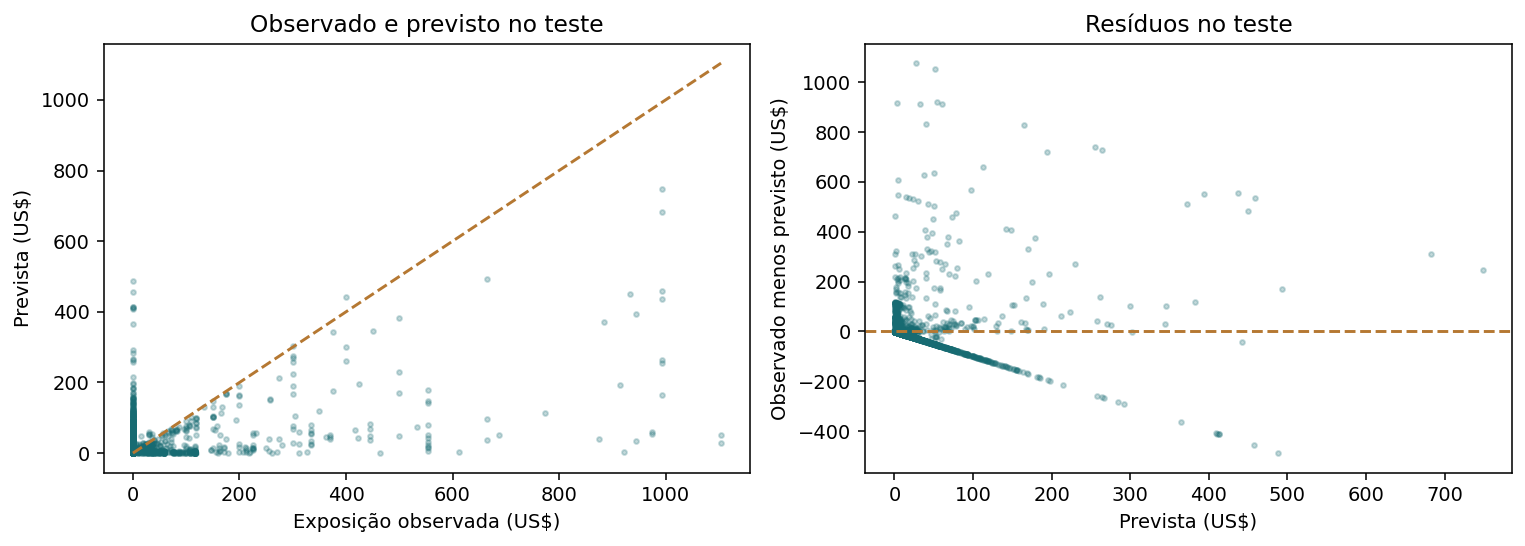

In [7]:
sel=DADOS['regression_selection.json']
print('Escolhido:',sel['winner'])
tabela([{'modelo':m,'MSE_validacao':-v} for m,v in sorted(sel['validation_selection_scores'].items(),key=lambda x:-x[1])])
tabela([r for r in DADOS['regression_metrics.csv'] if r['split']=='test'],['model','MAE','MSE','RMSE','R2'])
grafico('regression_residuals')

## 7. Métricas e duas seleções diferentes

**Pergunta:** “Por que não acurácia? Por que 241 e 114?”

**Resposta:** sempre prever legítima daria 96,67% de acurácia e recall zero. Precisão mede fraudes entre alertas; recall mede cobertura das fraudes; F1 equilibra ambos. AP resume a curva precisão–recall; AUC mede ordenação entre classes. Nenhuma dessas métricas equivale a valor monetário.

**Matriz HistGB:** TN=15.106, FP=279, FN=289 e TP=241, usando limiar bruto 0,20 selecionado por F1 na validação. Precisão ≈46,35%; recall ≈45,47%; F1≈0,459.

**Fila:** 333 análises e 114 fraudes, selecionadas por ranking diário de probabilidade calibrada × valor. O limiar gera 520 alertas, por outra regra. Não compare 241 com 114 como se tivessem o mesmo orçamento.

**Regressão:** MAE em dólares; MSE em dólares² penaliza erros grandes; RMSE volta a dólares; R² compara erro quadrático com referência baseada na média.

**Gráficos abaixo:** ROC confronta taxa de falsos positivos e recall; precisão–recall explicita o compromisso entre qualidade e cobertura dos alertas. A linha da prevalência na PR é referência, não limiar operacional. AP não é percentual de fraudes encontradas.

**Fonte:** matriz e métricas; original seções 8–9 e 11.

| diagnostico | alertas | fraudes_sinalizadas | precisao | recall | F1 |
| --- | --- | --- | --- | --- | --- |
| limiar 0,20 | 520 | 241 | 0.463462 | 0.454717 | 0.459048 |
| fila monetaria | 333 | 114 | 0.342342 | 0.215094 | objetivo principal e monetario |

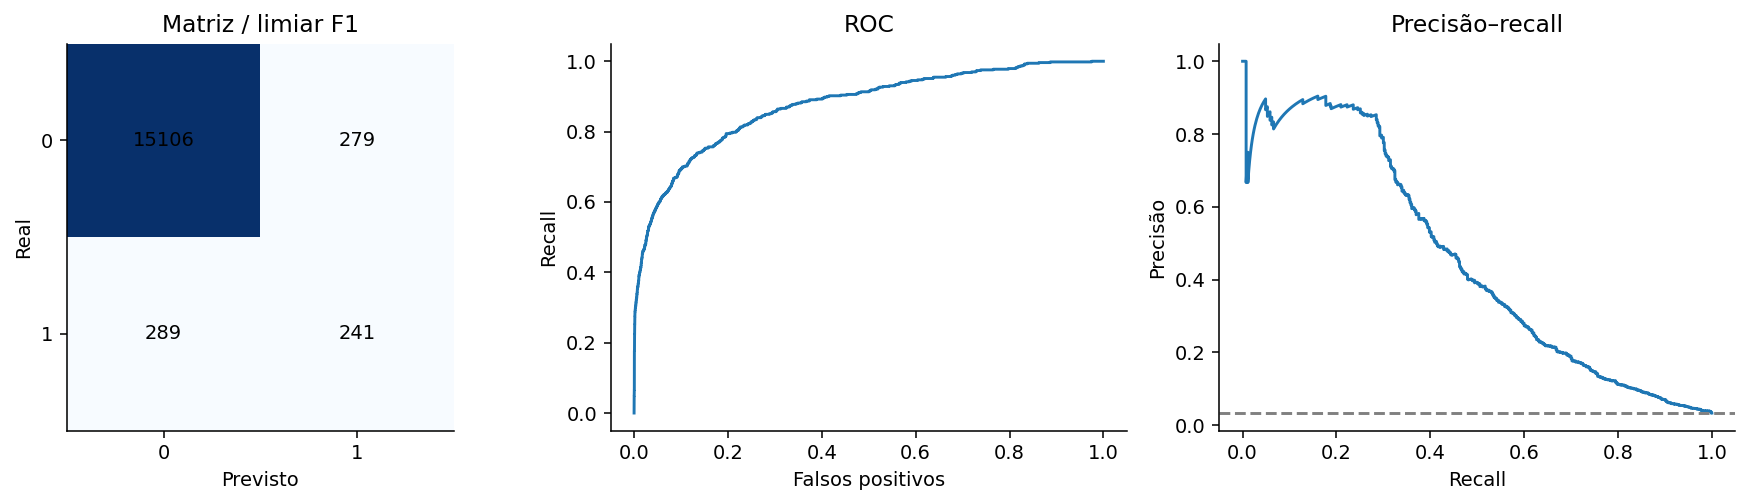

In [8]:
TN,FP,FN,TP=15106,279,289,241
precisao=TP/(TP+FP); recall=TP/(TP+FN)
tabela([{'diagnostico':'limiar 0,20','alertas':TP+FP,'fraudes_sinalizadas':TP,
 'precisao':precisao,'recall':recall,'F1':2*precisao*recall/(precisao+recall)},
 {'diagnostico':'fila monetaria','alertas':333,'fraudes_sinalizadas':114,
 'precisao':114/333,'recall':114/530,'F1':'objetivo principal e monetario'}])
assert TN+FP+FN+TP==15915
grafico('classification_diagnostics')

## 8. Calibração, importância e sobreajuste

**Pergunta:** “Para que calibrar? Qual variável importa? O modelo decorou?”

**Resposta:** discriminação ordena riscos; calibração aproxima probabilidades e frequências. Platt aprende uma transformação logística no bloco de calibração, sem retreinar o classificador com o teste.

**Resultado:** Brier bruto ≈0,023109 e calibrado ≈0,023080 no teste: melhora pequena. AP de ajuste ≈0,751 e teste ≈0,454 indica otimismo de ajuste; mudança temporal também pode contribuir. Não isolamos os efeitos.

**Importância por permutação:** embaralha uma entrada e mede piora na calibração, em 1.200 linhas com três repetições. Classificação: maior queda de AP para C1; regressão: maior aumento de RMSE para TransactionAmt. Não é causalidade e correlações podem dividir importância. Não usamos esse diagnóstico para refazer seleção de atributos pelo teste.

**Fonte:** métricas, diagnósticos e arquivos de permutação; original 10–11.

In [9]:
r=next(r for r in DADOS['classification_metrics.csv'] if r['split']=='test' and r['model']=='HistGradientBoosting')
tabela([r],['model','Brier','calibrated_Brier','AP'])
tabela(DADOS['permutation_importance.csv'][:4],['feature','importance','std'])
tabela(DADOS['regression_permutation_importance.csv'][:4],['feature','increase_RMSE_USD','std'])

| model | Brier | calibrated_Brier | AP |
| --- | --- | --- | --- |
| HistGradientBoosting | 0.023108953227230635 | 0.023080320650983442 | 0.4539997764698402 |

| feature | importance | std |
| --- | --- | --- |
| C1 | 0.20566972937744143 | 0.03071030682296319 |
| C14 | 0.08563751260117423 | 0.00516310057770247 |
| C13 | 0.038369415840405895 | 0.017247371507537433 |
| D15 | 0.03703000603681835 | 0.0035352998699293473 |

| feature | increase_RMSE_USD | std |
| --- | --- | --- |
| TransactionAmt | 14.60830434018677 | 2.353152542773336 |
| D2 | 5.434341887251638 | 0.06804302996569896 |
| card6 | 4.097153818284369 | 0.18165055819148418 |
| M4 | 3.832638856222921 | 2.9841441910946993 |

## 9. Agrupamento: quais são os grupos e o que PCA mostra

**Pergunta:** “k=2 significa fraude e legítima?”

**Resposta:** não. K-means formou dois grupos de transações semelhantes em nove indicadores preparados de duas mil transações de treino. Grupo 0: 1.880; grupo 1: 120. Ambos contêm fraudes e legítimas. Taxas posteriores: 4,52% e 6,67%. Números dos grupos são rótulos arbitrários.

**Métodos:** K-means minimiza distâncias quadráticas aos centros; hierárquico Ward une grupos por incremento de variância; DBSCAN usa densidade e ruído; PCA projeta em direções de maior variância. Comparamos k=2–6 e quatro eps. Silhouette maior e Davies–Bouldin menor ajudam, mas cobertura, escala e interpretação também importam.

**Resultado:** hierárquico k=2 silhouette 0,580/DB 0,756; K-means 0,552/0,833; DBSCAN eps=1,5 tem 9% de ruído. Duas componentes retêm 56,53%, cinco 89,02%; maiores pesos de PC1 em C13/C1/C2.

**Limites:** dois grupos não são duas classes; ruído não é fraude; não comprovamos retorno dos grupos. O gráfico 2D omite variância e não permite inventar perfis de negócio para atributos anônimos.

**Fonte:** resultados exploratórios; original seção 12.

In [10]:
tabela(DADOS['cluster_profiles.csv'])
tabela([r for r in DADOS['techniques_summary.csv'] if r['task']=='Exploração'],
       ['label','configuration','test_metric','limitation'])
tabela(DADOS['pca_variance.csv'])

| cluster | n | fraud_rate | amount |
| --- | --- | --- | --- |
| 0 | 1880 | 0.04521276595744681 | 136.3492760638298 |
| 1 | 120 | 0.06666666666666667 | 100.72124166666667 |

| label | configuration | test_metric | limitation |
| --- | --- | --- | --- |
| KMeans | k=2; n_init=15 | Sil=0.552; DB=0.833 | Escala e formato dos grupos |
| Hierárquico | Ward; k=2 | Sil=0.580; DB=0.756 | Corte e custo computacional |
| DBSCAN | eps=1.5; mín=10 | Sil=0.369; ruído=9% | Depende de eps e cobertura |
| PCA | 9 entradas; projeção 2D | 2 CP=56.53%; 5=89.02% | Não otimiza fraude ou lucro |

| component | variance | cumulative |
| --- | --- | --- |
| 1 | 0.4087918324123393 | 0.4087918324123393 |
| 2 | 0.15655114606889406 | 0.5653429784812334 |
| 3 | 0.119191580222467 | 0.6845345587037004 |
| 4 | 0.1083300317506169 | 0.7928645904543172 |
| 5 | 0.09736598565799713 | 0.8902305761123144 |
| 6 | 0.04752095969178586 | 0.9377515358041002 |
| 7 | 0.042388336190402595 | 0.9801398719945028 |
| 8 | 0.014849293856211811 | 0.9949891658507146 |
| 9 | 0.005010834149285248 | 0.9999999999999999 |

## 10. Benefício: o que foi identificado e o que foi simulado

**Pergunta:** “Quanto ganhamos? Por que não só maior risco?”

**Resposta:** maior risco encontra mais casos, mas risco × valor identifica mais exposição. Com as mesmas 333 análises: maiores valores encontra 17 fraudes/US$ 14.670; probabilidade encontra 194/US$ 21.299,71; risco × valor encontra 114/US$ 38.044,57.

**Hipóteses:** eficácia=80%, US$ 2 por análise e penalidade adicional zero por revisão legítima. Benefício líquido = eficácia × valor identificado − custo × análises. Incremento = benefício do modelo − benefício da referência.

**Conta:** modelo US$ 29.769,66; referência US$ 11.070; incremento US$ 18.699,66. A perda restante da referência é US$ 67.781,255; dividir o incremento por ela dá 27,59%. Não é ROI de implantação.

**Por que 333?** Capacidade de 2% arredondada para cima separadamente a cada dia. Custos unitários iguais cancelam na diferença com quantidades iguais; implantação e penalidades distintas não cancelam necessariamente.

**Fonte:** `financial_policies.csv`; original 13–15 e 24.4.

In [11]:
linhas=[r for r in DADOS['financial_policies.csv'] if r['scenario']=='central' and float(r['capacity'])==0.02]
tabela(linhas,['policy','fraud_reviewed','labeled_amount_captured','net_benefit'])
por={r['policy']:r for r in linhas};m=por['ML_ExpectedAmount'];b=por['LargestAmount']
ganho=float(m['net_benefit'])-float(b['net_benefit'])
print(f"Incremento simulado: US$ {ganho:,.2f}")
print(f"Reducao da perda simulada da referencia: {100*ganho/float(b['total_loss']):.2f}%")
assert abs(ganho-18699.6576)<1e-6

Incremento simulado: US$ 18,699.66
Reducao da perda simulada da referencia: 27.59%


| policy | fraud_reviewed | labeled_amount_captured | net_benefit |
| --- | --- | --- | --- |
| Random | 11 | 881.0259999999998 | 38.82079999999996 |
| LargestAmount | 17 | 14670.0 | 11070.0 |
| ProductRateAmount | 16 | 10290.014 | 7566.011199999999 |
| ML_Probability | 194 | 21299.713000000003 | 16373.770400000005 |
| ML_ExpectedAmount | 114 | 38044.572 | 29769.657600000002 |
| RegressionExposure | 105 | 36919.505000000005 | 28869.604000000007 |

## 11. Robustez: e se a eficácia for menor?

**Pergunta:** “O ganho é confiável? A logística já não resolvia?”

**Resposta:** bootstrap pareado circular com blocos de sete dias e 5.000 réplicas produziu intervalo exploratório de US$ 13.862,06 a US$ 23.765,04. Modelo e referência recebem os mesmos dias em cada réplica. Ainda temos apenas 28 dias; réplicas não criam novos períodos independentes.

**Sensibilidade:** eficácia de 50% mantém incremento ≈US$ 11.687,29. Não é eficácia medida. Custos maiores reduzem benefícios absolutos; com mesma quantidade, o custo por análise cancela na diferença.

**Referência de ML:** logística já produz valor. Contra ela, campeão acrescenta ≈US$ 7.132,38 e reduz a perda simulada em 12,69%. É diagnóstico adicional e não muda o campeão pelo teste.

**Limites:** intervalo não garante ganhos futuros, não incorpora todos os erros econômicos e não prova causalidade. Não anualizamos automaticamente.

**Fonte:** bootstrap e cenários; original seção 16.

In [12]:
tabela([DADOS['financial_bootstrap.json']])
from collections import defaultdict
grupos=defaultdict(dict)
for r in DADOS['financial_policies.csv']:
    if float(r['capacity'])==0.02: grupos[r['scenario']][r['policy']]=r
saida=[]
for c,g in grupos.items():
    m,b=g['ML_ExpectedAmount'],g['LargestAmount']
    saida.append({'cenario':c,'incremento_USD':float(m['net_benefit'])-float(b['net_benefit'])})
tabela(saida)
tabela([DADOS['logistic_comparator_bootstrap.json']])

| main_policy | comparator | capacity | incremental_benefit | ci95_low | ci95_high | days | block_days | note |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ML_ExpectedAmount | LargestAmount | 0.020000 | 18699.657600 | 13862.060780 | 23765.044720 | 28 | 7 | Exploratory paired circular bootstrap; few independent temporal blocks; no causal claim |

| cenario | incremento_USD |
| --- | --- |
| central | 18699.657600 |
| low_efficacy | 11687.286000 |
| high_cost | 18699.657600 |
| fp_penalty | 19669.657600 |

| candidate | reference | incremental_benefit | ci95_low | ci95_high | note |
| --- | --- | --- | --- | --- | --- |
| HistGradientBoosting | Logistic | 7132.379200 | 4357.875360 | 10016.030960 | Additional diagnostic after primary evaluation; does not replace original comparator or winner |

## 12. Ética, limitações e como responder sem inventar

**Pergunta:** “Isso já pode ser implantado?”

**Resposta:** os resultados justificam investigar um piloto, não implantação imediata. Precisamos de outros períodos, eficácia observada, atraso da ação, custos completos, monitoramento e avaliação de efeitos sobre clientes.

**Ética:** uma transação sinalizada não comprova que uma pessoa seja fraudadora. Investigação não equivale a bloqueio automático. Revisões de legítimas podem gerar atrito e tratamento desigual. Não medimos paridade entre grupos protegidos nem demonstramos conformidade jurídica. Dados públicos e anônimos não dispensam finalidade, privacidade, segurança e governança.

**Lacunas da apresentação principal e onde responder:** resíduos/importância da regressão no original 11; grades e CV no original 6–7; proveniência/licença no original 2; conta e cenários no original 14–16. A apresentação oficial mostra síntese; este apoio complementa detalhes.

**Demonstração:** no original 20 há logística didática com fit/predict, que não reproduz o campeão. No original 24.4 a conta lê os CSVs do estudo. Treinamento completo fica fora do tempo da fala.

**Três respostas honestas:** “Essa informação não consta da base”; “esse teste não foi realizado”; “essa é uma hipótese de cenário”.

**Não diga:** lucro recuperado, grupos de fraudadores, independência condicional rejeitada formalmente, teste totalmente inédito ou R² como percentual de fraudes.

**Fonte:** original 17, 20–24; documentação do projeto.

In [13]:
print('Checklist oral:')
for pergunta in [
 'Qual bloco escolheu o campeao? Validacao.',
 'Usamos CV? Sim, tres folds temporais dentro do treino.',
 'Lucro realizado? Nao, beneficio simulado sob hipoteses.',
 'k=2? Dois grupos sem rotulo na construcao.',
 'Teste inedito? Nao, revisao retrospectiva.',
 'Equidade demonstrada? Nao, risco discutido sem auditoria quantitativa.'
]: print('-',pergunta)

Checklist oral:
- Qual bloco escolheu o campeao? Validacao.
- Usamos CV? Sim, tres folds temporais dentro do treino.
- Lucro realizado? Nao, beneficio simulado sob hipoteses.
- k=2? Dois grupos sem rotulo na construcao.
- Teste inedito? Nao, revisao retrospectiva.
- Equidade demonstrada? Nao, risco discutido sem auditoria quantitativa.
